# CE 1110 - Tarea 1: caracterización espectral y prototipado de filtros

Estructura: 2.1 Fundamentos y FFT, 2.2 Señales, 2.3 Filtro FIR, 2.4 Filtrado espectral, 2.5 Comparación.
Código reutilizable en `src/` (`fft_propia.py`, `senales.py`, `metricas.py`, `filtros_temporales.py`,
`filtrado_espectral.py`, `graficas.py`). Ejecutar con *Run All* desde la carpeta raíz del entregable.

In [17]:
import csv, sys, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=RuntimeWarning)

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

import fft_propia as fp
import senales as sg
import metricas as mt
import filtros_temporales as ft
import filtrado_espectral as fe
import graficas as gr

FIG = RAIZ / "resultados" / "figuras"
for carpeta in (FIG, RAIZ / "metadatos"):
    carpeta.mkdir(parents=True, exist_ok=True)

C = sg.COMUN
fs, L, N = C["fs"], C["L"], C["N_bloque"]
HOP = N // 2                 # salto entre bloques (50 % de solapamiento)
E_RECORTE = N                # muestras que se descartan en cada extremo al medir
NOMBRES = ["caso_1", "caso_2", "caso_3"]
ROM = {"caso_1": "Uno", "caso_2": "Dos", "caso_3": "Tres"}
ETIQ = {"caso_1": "Caso 1", "caso_2": "Caso 2", "caso_3": "Caso 3"}
VAL = {}                     # valores que se exportan al informe como macros LaTeX
CONFIG = {}                  # metadatos que se guardan en configuraciones.json


def mostrar(ruta):
    display(Image(filename=str(ruta)))


MOSTRAR_TABLAS_TEX = True    # False: oculta las copias "versión LaTeX" y deja solo las tablas de pantalla


def _es_bool(v):
    return isinstance(v, (bool, np.bool_))


def _es_numero(v):
    return isinstance(v, (int, float, np.number)) and not _es_bool(v)


def imprimir_tabla(cabecera, filas, titulo=None, cifras=4, fmt=None):
    """Imprime una tabla alineada en texto plano.

    Números a la derecha y texto a la izquierda; bool se muestra como sí/NO y NaN como "--".
    Los float usan `cifras` cifras significativas, salvo que `fmt` dé un formato por columna
    (lista con None o un formato como ".2f").
    """
    fmt = fmt or [None] * len(cabecera)
    for f in filas:
        if len(f) != len(cabecera):
            raise ValueError(f"fila con {len(f)} celdas y {len(cabecera)} columnas: {f}")

    def celda(v, formato):
        if _es_bool(v):
            return "sí" if v else "NO"
        if isinstance(v, (float, np.floating)):
            return "--" if np.isnan(v) else format(v, formato or f".{cifras}g")
        return str(v)

    texto = [[celda(v, fmt[j]) for j, v in enumerate(f)] for f in filas]
    numerica = [all(_es_numero(f[j]) for f in filas) for j in range(len(cabecera))]
    ancho = [max([len(str(h))] + [len(f[j]) for f in texto]) for j, h in enumerate(cabecera)]

    def linea(valores):
        return "  ".join(v.rjust(a) if num else v.ljust(a) for v, a, num in zip(valores, ancho, numerica))

    if titulo:
        print(f"\n{titulo}")
    print(linea([str(h) for h in cabecera]))
    print("  ".join("-" * a for a in ancho))
    for f in texto:
        print(linea(f))


def tabla_tex(nombre, cabecera, filas, alin=None):
    """Muestra la tabla en su versión LaTeX (las tablas del informe se editan en el .tex).
    `alin` se conserva por compatibilidad: la alineación la define el informe."""
    if MOSTRAR_TABLAS_TEX:
        imprimir_tabla(cabecera, [[str(c) for c in f] for f in filas], titulo=f"[{nombre}]  versión LaTeX")


def guardar_csv(ruta, columnas, filas, formato_float="%.6g"):
    """Escribe un CSV UTF-8. `filas` es una lista de diccionarios.
    NaN queda como celda vacía; los float usan `formato_float` (None = representación completa)."""
    def valor(v):
        if isinstance(v, (float, np.floating)):
            if np.isnan(v):
                return ""
            return formato_float % v if formato_float else repr(float(v))
        return v

    with open(ruta, "w", newline="", encoding="utf-8") as fh:
        w = csv.writer(fh, lineterminator="\n")
        w.writerow(columnas)
        for f in filas:
            w.writerow([valor(f.get(c, "")) for c in columnas])


def macro(nombre, valor, fmt="{:.2f}"):
    nuevo = valor if isinstance(valor, str) else fmt.format(valor)
    if VAL.get(nombre, nuevo) != nuevo:
        warnings.warn(f"la macro '{nombre}' se sobrescribe ({VAL[nombre]} -> {nuevo}): revisar nombres repetidos", stacklevel=2)
    VAL[nombre] = nuevo


def sci(v, d=1):
    m, e = f"{v:.{d}e}".split("e")
    return rf"${m}\times10^{{{int(e)}}}$"


def medir_ms(fn, rep=30):
    ts = []
    for _ in range(rep):
        t0 = time.perf_counter()
        fn()
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts) * 1000)


print(f"fs = {fs} Hz | L = {L} muestras ({L / fs:.3f} s) | bloque N = {N} | salto = {HOP}")

fs = 8000 Hz | L = 16384 muestras (2.048 s) | bloque N = 512 | salto = 256


## 2.1 Fundamentos, muestreo y FFT

### (a) Serie de Fourier, DFT y FFT: ejemplo numérico

Se toma $x(t)=1+2\cos(2\pi\,1000\,t)+0.5\sin(2\pi\,2000\,t)$, periódica con $T_0=1$ ms, muestreada a
$f_s=8$ kHz con $N=64$ (8 periodos exactos). Los coeficientes de la serie exponencial son
$c_0=1,\; c_{\pm1}=1,\; c_{2}=-0.25j,\; c_{-2}=+0.25j$. La DFT de un periodo debe cumplir $X[k]/N=c_m$
con $k=m\,f_0/\Delta f$ (módulo $N$).

In [18]:
Nej = 64
t = np.arange(Nej) / fs
x_ej = 1 + 2 * np.cos(2 * np.pi * 1000 * t) + 0.5 * np.sin(2 * np.pi * 2000 * t)
X_ej = fp.fft(x_ej)                       # FFT propia
df_ej = fs / Nej                          # 125 Hz
c_teo = {0: 1.0, 1: 1.0, -1: 1.0, 2: -0.25j, -2: 0.25j}

def cplx(z):
    z = complex(z)
    re, im = round(z.real, 3) + 0.0, round(z.imag, 3) + 0.0      # "+ 0.0" evita imprimir -0.000
    if abs(z.imag) < 5e-4:
        return f"{re:.3f}"
    return f"{re:.3f}{im:+.3f}j"

filas, filas_tex = [], []
for m, ct in c_teo.items():
    k = int(round(m * 1000 / df_ej)) % Nej
    ck = X_ej[k] / Nej
    filas.append([m, k, cplx(ct), cplx(ck), abs(ck - ct)])
    filas_tex.append([m, k, f"${cplx(ct)}$", f"${cplx(ck)}$", sci(abs(ck - ct) + 1e-17)])
imprimir_tabla(["m", "bin k", "c_m teórico", "X[k]/N", "|error|"], filas, titulo="Serie de Fourier vs. DFT (N = 64)")
tabla_tex("tabla_fourier", ["$m$", "bin $k$", "$c_m$ (serie)", "$X[k]/N$ (DFT)", "$|$error$|$"], filas_tex, "rrccc")
macro("errFourier", max(abs(X_ej[int(round(m * 1000 / df_ej)) % Nej] / Nej - ct) for m, ct in c_teo.items()), "{:.1e}")

# --- DFT directa vs FFT: exactitud y costo --------------------------------
rng = np.random.default_rng(1)
filas, filas_tex = [], []
for Nt in [256, 512, 1024, 2048]:
    xr = rng.standard_normal(Nt)
    Xd, Xf, Xn = fp.dft_directa(xr), fp.fft(xr), np.fft.fft(xr)
    err_df = np.max(np.abs(Xd - Xf))
    err_fn = np.max(np.abs(Xf - Xn))
    t_d = medir_ms(lambda: fp.dft_directa(xr), 3)
    t_f = medir_ms(lambda: fp.fft(xr), 20)
    t_n = medir_ms(lambda: np.fft.fft(xr), 200)
    mult_dft, mult_fft = Nt ** 2, int((Nt / 2) * np.log2(Nt))
    filas.append([Nt, mult_dft, mult_fft, t_d, t_f, t_n, err_df, err_fn])
    filas_tex.append([Nt, f"{mult_dft:,}".replace(",", r"\,"), f"{mult_fft:,}".replace(",", r"\,"),
                      f"{t_d:.1f}", f"{t_f:.2f}", f"{t_n:.3f}", sci(err_df), sci(err_fn)])
    if Nt == 512:
        macro("errDftFft", err_df, "{:.1e}"); macro("errFftNumpy", err_fn, "{:.1e}")
imprimir_tabla(["N", "mult DFT N^2", "mult FFT (N/2)log2N", "t DFT [ms]",
                "t FFT propia [ms]", "t numpy [ms]", "max|DFT-FFT|", "max|FFT-numpy|"],
               filas, titulo="DFT directa vs. FFT: exactitud y costo")
tabla_tex("tabla_dft_fft", ["$N$", r"$N^2$", r"$\frac{N}{2}\log_2 N$", "DFT [ms]", "FFT propia [ms]",
                            "numpy [ms]", r"$\max|$DFT$-$FFT$|$", r"$\max|$FFT$-$numpy$|$"], filas_tex, "rrrrrrcc")


Serie de Fourier vs. DFT (N = 64)
 m  bin k  c_m teórico   X[k]/N          |error|
--  -----  ------------  ------------  ---------
 0      0  1.000         1.000         6.661e-16
 1      8  1.000         1.000         2.103e-15
-1     56  1.000         1.000         2.159e-15
 2     16  0.000-0.250j  0.000-0.250j  6.157e-16
-2     48  0.000+0.250j  0.000+0.250j   6.32e-16

[tabla_fourier]  versión LaTeX
$m$  bin $k$  $c_m$ (serie)   $X[k]/N$ (DFT)  $|$error$|$        
---  -------  --------------  --------------  -------------------
0    0        $1.000$         $1.000$         $6.8\times10^{-16}$
1    8        $1.000$         $1.000$         $2.1\times10^{-15}$
-1   56       $1.000$         $1.000$         $2.2\times10^{-15}$
2    16       $0.000-0.250j$  $0.000-0.250j$  $6.3\times10^{-16}$
-2   48       $0.000+0.250j$  $0.000+0.250j$  $6.4\times10^{-16}$

DFT directa vs. FFT: exactitud y costo
   N  mult DFT N^2  mult FFT (N/2)log2N  t DFT [ms]  t FFT propia [ms]  t numpy [ms]  ma

### (b) Resolución $\Delta f = f_s/N = 1/T$, latencia y memoria

Con $f_s=8$ kHz se tabula el compromiso. Con ventana Hann dos tonos se distinguen si su separación es
mayor que ~$2\Delta f$ (lóbulo principal de 4 bins entre nulos). Se comprueba con tonos en 1000 y 1030 Hz.


Resolución, latencia y memoria según N
   N   Δf [Hz]  T=N/fs [ms]  salto T/2 [ms]  RAM ≈16N B [kB]
----  --------  -----------  --------------  ---------------
  64  125.0000          8.0             4.0              1.0
 128   62.5000         16.0             8.0              2.0
 256   31.2500         32.0            16.0              4.0
 512   15.6250         64.0            32.0              8.0
1024    7.8125        128.0            64.0             16.0
2048    3.9062        256.0           128.0             32.0
4096    1.9531        512.0           256.0             64.0

[tabla_resolucion]  versión LaTeX
$N$   $\Delta f$ [Hz]  $T=N/f_s$ [ms]  Salto $T/2$ [ms]  RAM $\approx 16N$ B [kB]
----  ---------------  --------------  ----------------  ------------------------
64    125.00           8.0             4.0               1.0                     
128   62.50            16.0            8.0               2.0                     
256   31.25            32.0            16.0     

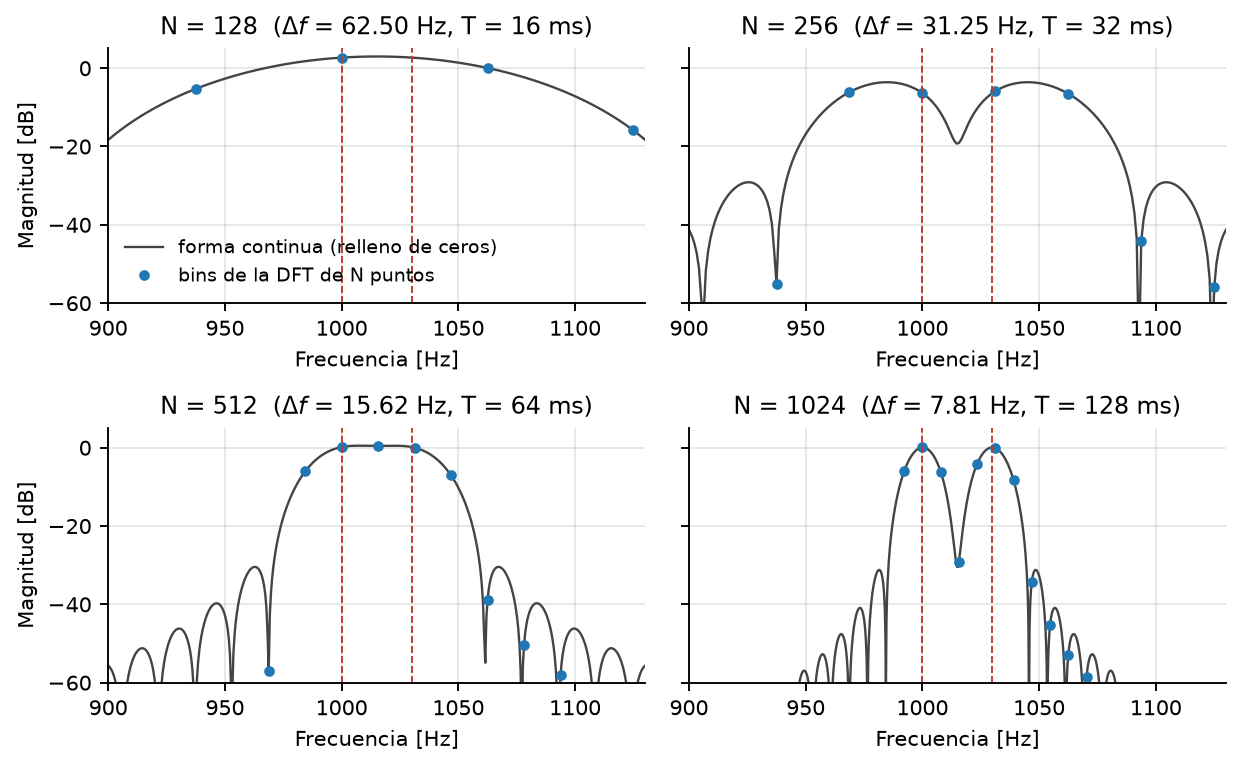

In [19]:
filas, filas_tex = [], []
for Nb in [64, 128, 256, 512, 1024, 2048, 4096]:
    T_ms = 1000 * Nb / fs
    filas.append([Nb, fs / Nb, T_ms, T_ms / 2, 16 * Nb / 1024])
    filas_tex.append([Nb, f"{fs / Nb:.2f}", f"{T_ms:.1f}", f"{T_ms / 2:.1f}", f"{16 * Nb / 1024:.1f}"])
imprimir_tabla(["N", "Δf [Hz]", "T=N/fs [ms]", "salto T/2 [ms]", "RAM ≈16N B [kB]"], filas,
               titulo="Resolución, latencia y memoria según N", fmt=[None, ".4f", ".1f", ".1f", ".1f"])
tabla_tex("tabla_resolucion", ["$N$", r"$\Delta f$ [Hz]", "$T=N/f_s$ [ms]", "Salto $T/2$ [ms]", r"RAM $\approx 16N$ B [kB]"],
          filas_tex, "rrrrr")
gr.fig_resolucion(fs, 1000.0, 1030.0, [128, 256, 512, 1024], FIG / "fig_2_1_resolucion.png")
mostrar(FIG / "fig_2_1_resolucion.png")
macro("dfBloque", fs / N); macro("TBloque", 1000 * N / fs, "{:.0f}")

### (c) Fuga espectral: tono en un bin vs. entre dos bins, rectangular vs. Hann

$N=512$, $f_s=8$ kHz: tono alineado en $k=64$ (1000 Hz) y tono entre bins en $k=64.5$ (1007.8125 Hz), fase inicial $\pi/4$.
La magnitud se normaliza por $A\sum w[n]/2$, de modo que 0 dB es la amplitud verdadera del tono.

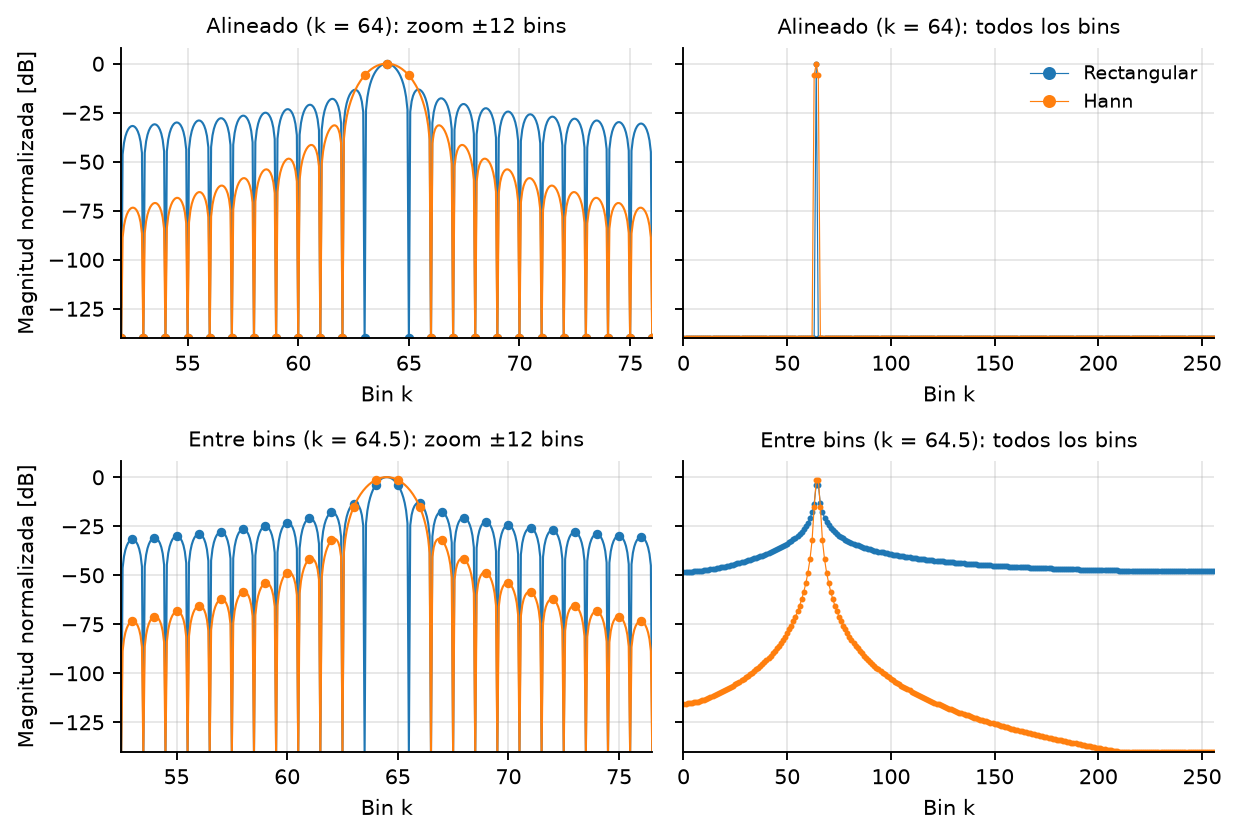

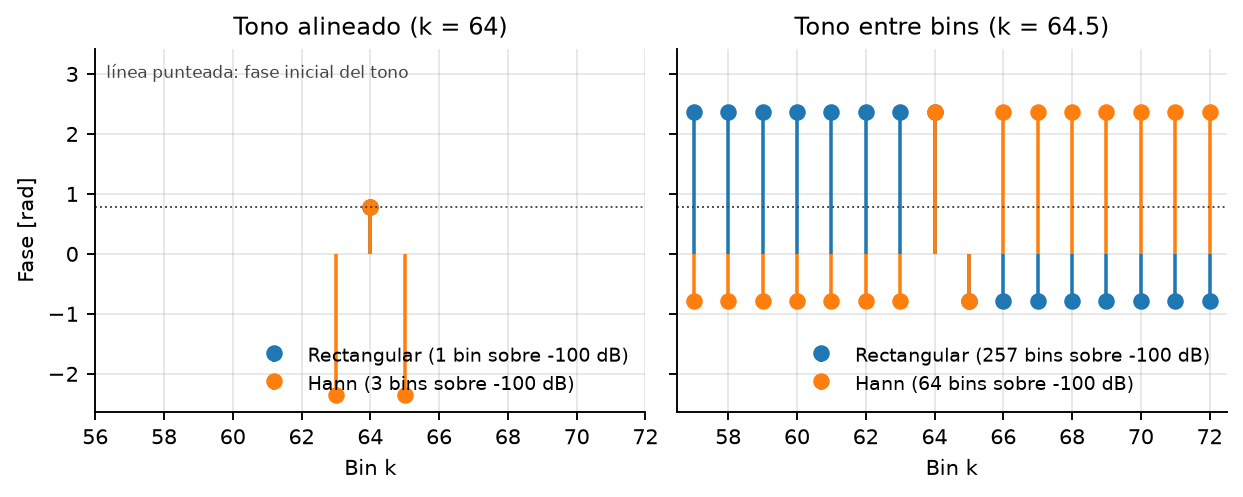


Fuga espectral: rectangular vs. Hann
ventana      ancho -3dB [bins]  nulo-nulo [bins]  lóbulo lateral [dB]  caída [dB/oct]  pérdida entre bins [dB]  fuera ±2 bins alineado [%]  fuera ±2 bins entre bins [%]
-----------  -----------------  ----------------  -------------------  --------------  -----------------------  --------------------------  ----------------------------
Rectangular             0.8858                 2               -13.26               6                   -3.896                   1.368e-26                         8.267
Hann                     1.441                 4               -31.47              18                   -1.424                   1.269e-26                        0.0506

[tabla_ventanas_a]  versión LaTeX
Ventana      Ancho $-3$ dB [bins (Hz)]  Nulo a nulo [bins (Hz)]  Lóbulo lateral máx. [dB]  Caída [dB/oct]
-----------  -------------------------  -----------------------  ------------------------  --------------
Rectangular  0.89 (13.8)               

In [20]:
k_al, k_fu, phi = 64, 64.5, np.pi / 4
gr.fig_ventanas_magnitud(N, fs, k_al, k_fu, phi, FIG / "fig_2_1_ventanas_magnitud.png")
gr.fig_ventanas_fase(N, k_al, k_fu, phi, FIG / "fig_2_1_ventanas_fase.png")
mostrar(FIG / "fig_2_1_ventanas_magnitud.png")
mostrar(FIG / "fig_2_1_ventanas_fase.png")

ventanas = {"Rectangular": np.ones(N), "Hann": fe.ventana_hann(N)}

def fuga(k0, w):
    n = np.arange(N)
    x = np.cos(2 * np.pi * k0 * n / N + phi)
    X = fp.fft(x * w)[: N // 2 + 1]
    pico_db = 20 * np.log10(np.abs(X).max() / (np.sum(w) / 2))     # 0 dB = amplitud verdadera
    P = np.abs(X) ** 2
    kc = int(np.argmax(P))
    fuera = P[np.abs(np.arange(N // 2 + 1) - kc) > 2].sum() / P.sum()
    return pico_db, 100 * fuera

filas, filas_tex = [], []
for nom, w in ventanas.items():
    m = fp.medidas_lobulos(w)
    p_al, f_al = fuga(k_al, w)
    p_fu, f_fu = fuga(k_fu, w)
    caida = 6 if nom == "Rectangular" else 18
    filas.append([nom, m["ancho_3dB_bins"], m["ancho_nulo_a_nulo_bins"], m["lobulo_lateral_dB"], caida, p_fu, f_al, f_fu])
    filas_tex.append([nom, f"{m['ancho_3dB_bins']:.2f} ({m['ancho_3dB_bins'] * fs / N:.1f})",
                      f"{m['ancho_nulo_a_nulo_bins']:.1f} ({m['ancho_nulo_a_nulo_bins'] * fs / N:.0f})",
                      f"{m['lobulo_lateral_dB']:.1f}", caida, f"{p_fu:.2f}", f"{f_al:.3f}", f"{f_fu:.3f}"])
    macro("lobuloLat" + nom[:3], m["lobulo_lateral_dB"], "{:.1f}")
    macro("picoFuera" + nom[:3], p_fu); macro("fugaFuera" + nom[:3], f_fu, "{:.3f}")
imprimir_tabla(["ventana", "ancho -3dB [bins]", "nulo-nulo [bins]", "lóbulo lateral [dB]",
                "caída [dB/oct]", "pérdida entre bins [dB]", "fuera ±2 bins alineado [%]",
                "fuera ±2 bins entre bins [%]"], filas, titulo="Fuga espectral: rectangular vs. Hann")
tabla_tex("tabla_ventanas_a", ["Ventana", "Ancho $-3$ dB [bins (Hz)]", "Nulo a nulo [bins (Hz)]", "Lóbulo lateral máx. [dB]", "Caída [dB/oct]"],
          [r[:5] for r in filas_tex], "lcccc")
tabla_tex("tabla_ventanas_b", ["Ventana", "Pérdida por picoteo, tono entre bins [dB]", r"Energía fuera de $\pm2$ bins, alineado [\%]", r"Energía fuera de $\pm2$ bins, entre bins [\%]"],
          [[r[0]] + r[5:] for r in filas_tex], "lccc")

### (d) Simetría conjugada de la DFT para señales reales

Para $x[n]\in\mathbb{R}$: $X[N-k]=X^*[k]$. Se verifica numéricamente y se muestra qué ocurre en la IFFT si se
modifica solo un lado del espectro.

max|X[N-k]-conj(X[k])| tonos: 3.55e-15 | aleatoria: 8.19e-15
IFFT con un solo lado modificado: max|Im y| = 0.478, amplitud residual del tono (parte real) = 0.500
IFFT con espejo:                  max|Im y| = 6.50e-17, amplitud residual del tono = 5.52e-18


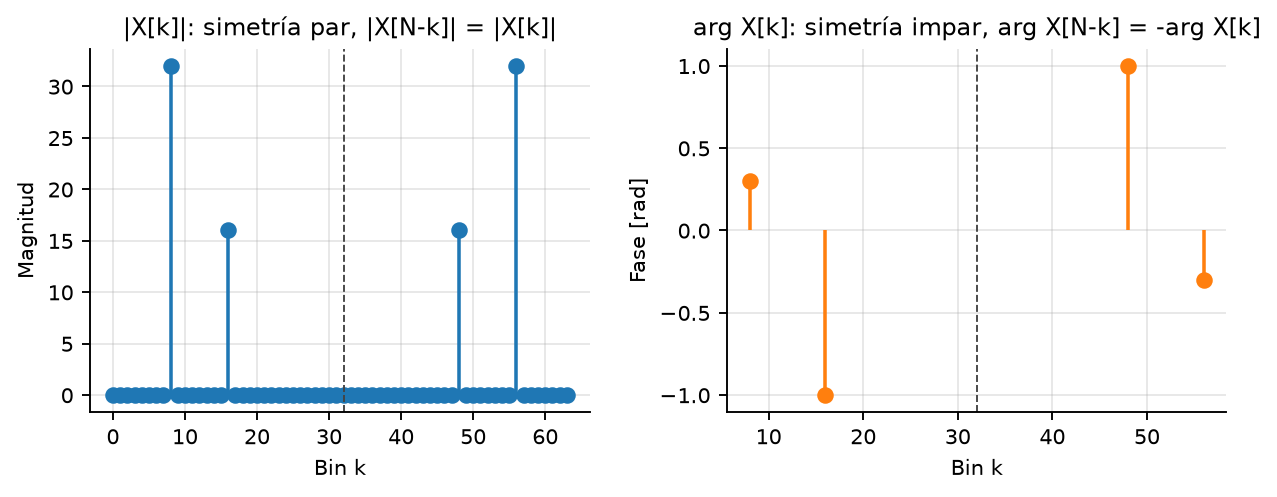


[tabla_simetria]  versión LaTeX
Operación sobre el espectro           $\max|\mathrm{Im}\{y[n]\}|$  Amplitud residual del tono eliminado
------------------------------------  ---------------------------  ------------------------------------
Anular solo $X[8]$ (sin espejo)       0.478                        0.50 (50 \%)                        
Anular $X[8]$ y $X[56]$ (con espejo)  $6.6\times10^{-17}$          $6.5\times10^{-18}$                 


In [21]:
Ns_ = 64
n = np.arange(Ns_)
xs = np.cos(2 * np.pi * 8 * n / Ns_ + 0.3) + 0.5 * np.cos(2 * np.pi * 16 * n / Ns_ - 1.0)
Xs = fp.fft(xs)
k = np.arange(1, Ns_)
err_sim = np.max(np.abs(Xs[Ns_ - k] - np.conj(Xs[k])))
# señal real aleatoria (comprobación general)
xr = np.random.default_rng(7).standard_normal(Ns_)
Xr = fp.fft(xr)
err_sim_rand = np.max(np.abs(Xr[Ns_ - k] - np.conj(Xr[k])))

Xm = Xs.copy(); Xm[8] = 0                      # anular el bin 8 SIN su espejo (56)
y_mal = fp.ifft(Xm)
Xc = Xs.copy(); Xc[8] = 0; Xc[Ns_ - 8] = 0     # anular el bin 8 Y su espejo
y_bien = fp.ifft(Xc)
amp_resid_mal = np.abs(fp.fft(y_mal.real)[8]) / (Ns_ / 2)       # amplitud residual del tono eliminado
amp_resid_bien = np.abs(fp.fft(y_bien.real)[8]) / (Ns_ / 2)
print(f"max|X[N-k]-conj(X[k])| tonos: {err_sim:.2e} | aleatoria: {err_sim_rand:.2e}")
print(f"IFFT con un solo lado modificado: max|Im y| = {np.max(np.abs(y_mal.imag)):.3f}, amplitud residual del tono (parte real) = {amp_resid_mal:.3f}")
print(f"IFFT con espejo:                  max|Im y| = {np.max(np.abs(y_bien.imag)):.2e}, amplitud residual del tono = {amp_resid_bien:.2e}")
gr.fig_simetria(Ns_, xs, FIG / "fig_2_1_simetria.png")
mostrar(FIG / "fig_2_1_simetria.png")
macro("errSim", max(err_sim, err_sim_rand), "{:.1e}")
macro("imagMal", np.max(np.abs(y_mal.imag)), "{:.3f}"); macro("imagBien", np.max(np.abs(y_bien.imag)), "{:.1e}")
macro("ampResMal", amp_resid_mal, "{:.2f}"); macro("ampResBien", amp_resid_bien, "{:.1e}")
tabla_tex("tabla_simetria", ["Operación sobre el espectro", r"$\max|\mathrm{Im}\{y[n]\}|$", "Amplitud residual del tono eliminado"],
          [["Anular solo $X[8]$ (sin espejo)", f"{np.max(np.abs(y_mal.imag)):.3f}", f"{amp_resid_mal:.2f} (50 \\%)"],
           ["Anular $X[8]$ y $X[56]$ (con espejo)", sci(np.max(np.abs(y_bien.imag)) + 1e-18), sci(amp_resid_bien + 1e-18)]], "lcc")

## 2.2 Generación y caracterización de señales

Se usa el generador del notebook guía (`CE1110_generador_tonos_defensa_Kaggle.ipynb`): sus funciones
(`generar_limpia`, `generar_ruido`, `escalar_ruido_para_snr`, `fade`, `normalizar_conjunto`) están en `src/senales.py`
y se llaman con la misma cadena y los mismos parámetros:
`TIPO_SENAL='multitono'`, `FRECUENCIAS_UTILES=[500,1200,2000]`, `AMPLITUDES_UTILES=[1,0.7,0.5]`,
`FASES_UTILES_GRADOS=[0,35,-50]`, `SNR_OBJETIVO_DB=5`, `PICO_MAXIMO=0.8`, `FADE_MS=20`. Lo que cambia entre casos es
`SEMILLA` (101, 202, 303) y `TIPO_RUIDO` (`'tonal'` con `FRECUENCIA_INTERFERENCIA=3100`, `'blanco'` y `'banda'` con
`BANDA_RUIDO=(1800,2800)`). Se cambió `FS` a 8 kHz y la duración a 2.048 s ($L=16384=2^{14}$).
Las señales limpia, ruido y contaminada se guardan como WAV de 16 bits en `pruebas/caso_i/`

In [22]:
datos, filas_snr_tex, filas_snr = {}, [], []
ARCH = {"limpia": "01_referencia_limpia.wav", "ruido": "02_ruido.wav", "contaminada": "03_entrada_contaminada.wav"}
CONFIG["comun"] = dict(C)
CONFIG["casos"] = {}
for nombre in NOMBRES:
    cfg = sg.CASOS[nombre]
    d = sg.generar_caso(cfg)
    datos[nombre] = d
    carpeta = RAIZ / "pruebas" / nombre
    carpeta.mkdir(parents=True, exist_ok=True)
    for clave, nom in ARCH.items():
        sg.guardar_wav(carpeta / nom, d[clave], fs)
    _, s_w = sg.cargar_wav(carpeta / ARCH["limpia"])
    _, x_w = sg.cargar_wav(carpeta / ARCH["contaminada"])
    snr_f = sg.snr_db(d["limpia"], d["contaminada"])
    snr_w = sg.snr_db(s_w, x_w)
    obj = cfg["snr_objetivo_db"]
    dif_suma = np.max(np.abs(d["contaminada"] - (d["limpia"] + d["ruido"])))
    filas_snr.append([nombre, obj, snr_f, snr_w, abs(snr_f - obj), abs(snr_w - obj)])
    filas_snr_tex.append([nombre.replace("caso_", ""), f"{obj:.1f}", f"{snr_f:.12f}", f"{snr_w:.4f}",
                          sci(abs(snr_f - obj) + 1e-16, 0), f"{abs(snr_w - obj):.1e}"])
    CONFIG["casos"][nombre] = {**cfg, "snr_obtenida_float64_db": snr_f, "snr_obtenida_wav_int16_db": snr_w,
                               "factor_escala_comun": d["factor_escala"],
                               "fases_iniciales_rad": [float(v) for v in d["fases_rad"]],
                               "archivos": {c: f"pruebas/{nombre}/{ARCH[c]}" for c in ARCH}}
    # metadatos del caso
    sg.guardar_json(carpeta / "metadatos_prueba.json", {
        "nombre_prueba": nombre, "modo": "manual", "semilla": cfg["seed"], "fs_Hz": fs, "duracion_s": L / fs,
        "tipo_senal": C["tipo_senal"], "frecuencias_utiles_Hz": C["frecuencias_utiles_hz"],
        "amplitudes_utiles": C["amplitudes"], "fases_grados": C["fases_grados"],
        "tipo_ruido": cfg["tipo_ruido"], "snr_objetivo_dB": cfg["snr_objetivo_db"], "snr_obtenida_dB": snr_f,
        "frecuencia_interferencia_Hz": cfg.get("f_interferencia_hz"), "banda_ruido_Hz": cfg.get("banda_ruido_hz"),
        "pico_maximo": C["pico_maximo"], "ganancia_comun": d["factor_escala"]})
    macro("snrWav" + ROM[nombre], snr_w, "{:.4f}"); macro("difWav" + ROM[nombre], abs(snr_w - obj), "{:.1e}")
    macro("snrFloat" + ROM[nombre], snr_f, "{:.10f}"); macro("difFloat" + ROM[nombre], abs(snr_f - obj), "{:.0e}")
    print(f"{nombre}: SNR objetivo {obj} dB | obtenida (float64) {snr_f:.12f} | desde WAV int16 {snr_w:.4f} "
          f"| max|x-(s+n)| = {dif_suma:.1e} | pico = {np.abs(d['contaminada']).max():.3f}")

imprimir_tabla(["caso", "SNR obj", "SNR float64", "SNR WAV", "|dif| float", "|dif| WAV"], filas_snr,
               titulo="SNR objetivo vs. obtenida", fmt=[None, ".1f", ".6f", ".4f", None, None])
desc = {"caso_1": r"Interferencia senoidal, $f_{int}=3100$ Hz",
        "caso_2": "Ruido blanco gaussiano (0--4000 Hz)",
        "caso_3": "Ruido de banda limitada, 1800--2800 Hz"}
tabla_tex("tabla_casos", ["Caso", "Tipo de ruido", "SNR obj. [dB]", "Semilla"],
          [[n.replace("caso_", ""), desc[n], f"{sg.CASOS[n]['snr_objetivo_db']:.1f}", sg.CASOS[n]["seed"]] for n in NOMBRES], "clcc")
tabla_tex("tabla_snr", ["Caso", "Objetivo [dB]", "Obtenida (float64) [dB]", "Obtenida (WAV 16 bits) [dB]",
                        r"$|\Delta|$ float64 [dB]", r"$|\Delta|$ WAV [dB]"], filas_snr_tex, "crrrrr")
macro("Lmuestras", str(L)); macro("durSeg", L / fs, "{:.3f}")

caso_1: SNR objetivo 5.0 dB | obtenida (float64) 5.000000000000 | desde WAV int16 4.9999 | max|x-(s+n)| = 1.1e-16 | pico = 0.800
caso_2: SNR objetivo 5.0 dB | obtenida (float64) 5.000000000000 | desde WAV int16 4.9999 | max|x-(s+n)| = 1.1e-16 | pico = 0.800
caso_3: SNR objetivo 5.0 dB | obtenida (float64) 5.000000000000 | desde WAV int16 5.0000 | max|x-(s+n)| = 1.1e-16 | pico = 0.800

SNR objetivo vs. obtenida
caso    SNR obj  SNR float64  SNR WAV  |dif| float  |dif| WAV
------  -------  -----------  -------  -----------  ---------
caso_1      5.0     5.000000   4.9999    1.243e-14   0.000111
caso_2      5.0     5.000000   4.9999    7.994e-15  8.502e-05
caso_3      5.0     5.000000   5.0000    1.688e-14   2.73e-05

[tabla_casos]  versión LaTeX
Caso  Tipo de ruido                              SNR obj. [dB]  Semilla
----  -----------------------------------------  -------------  -------
1     Interferencia senoidal, $f_{int}=3100$ Hz  5.0            101    
2     Ruido blanco gaussiano (

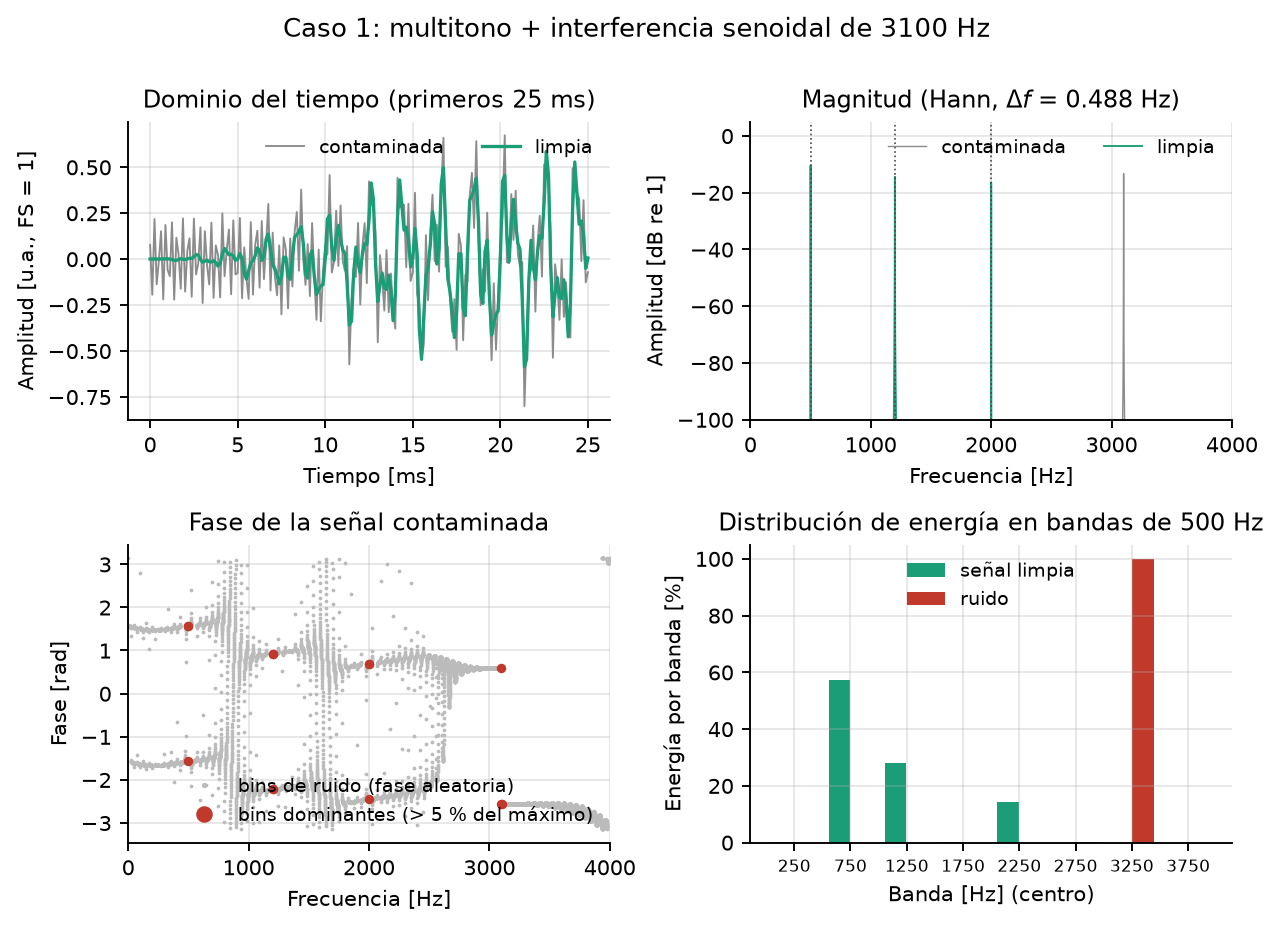

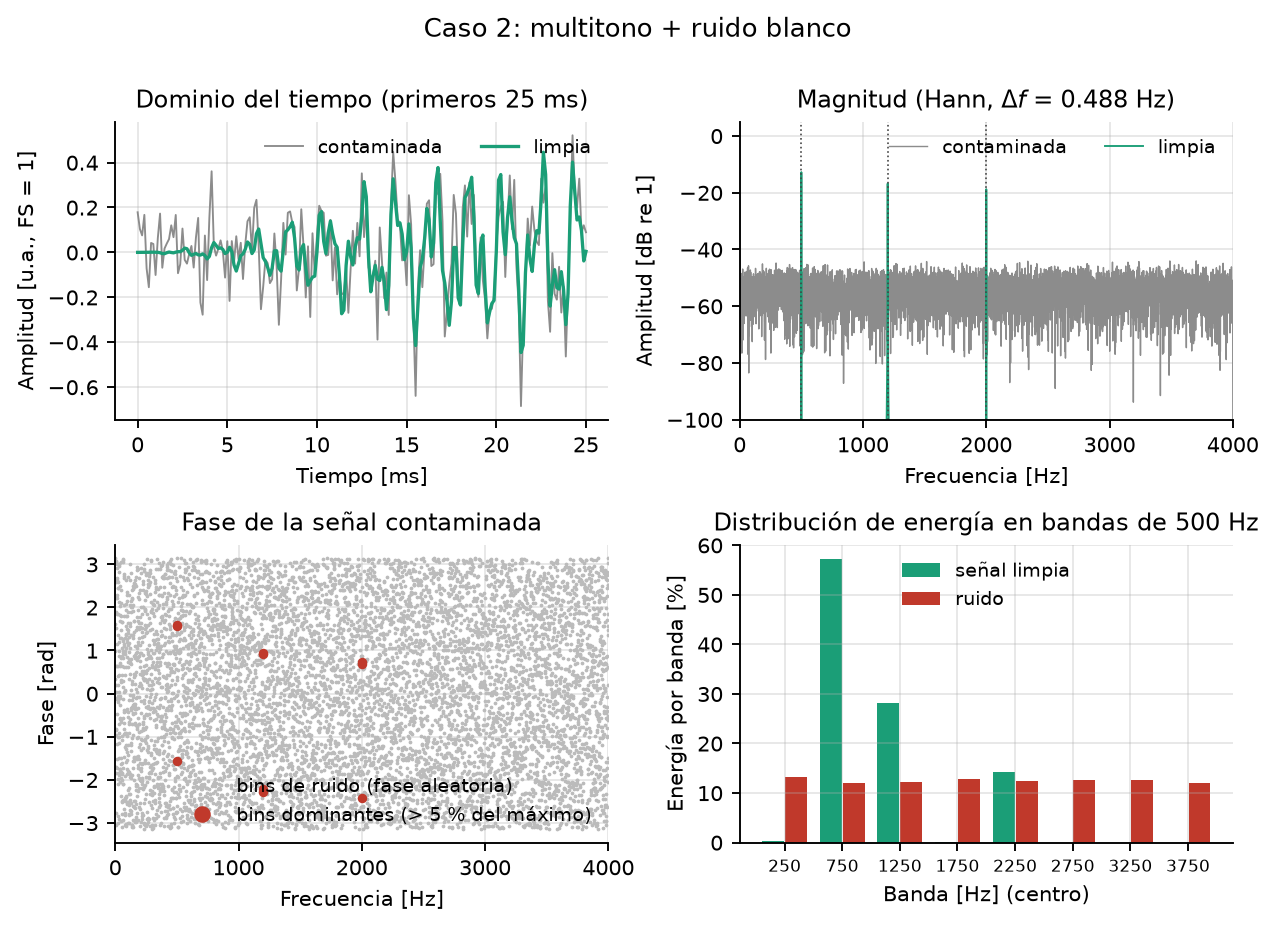

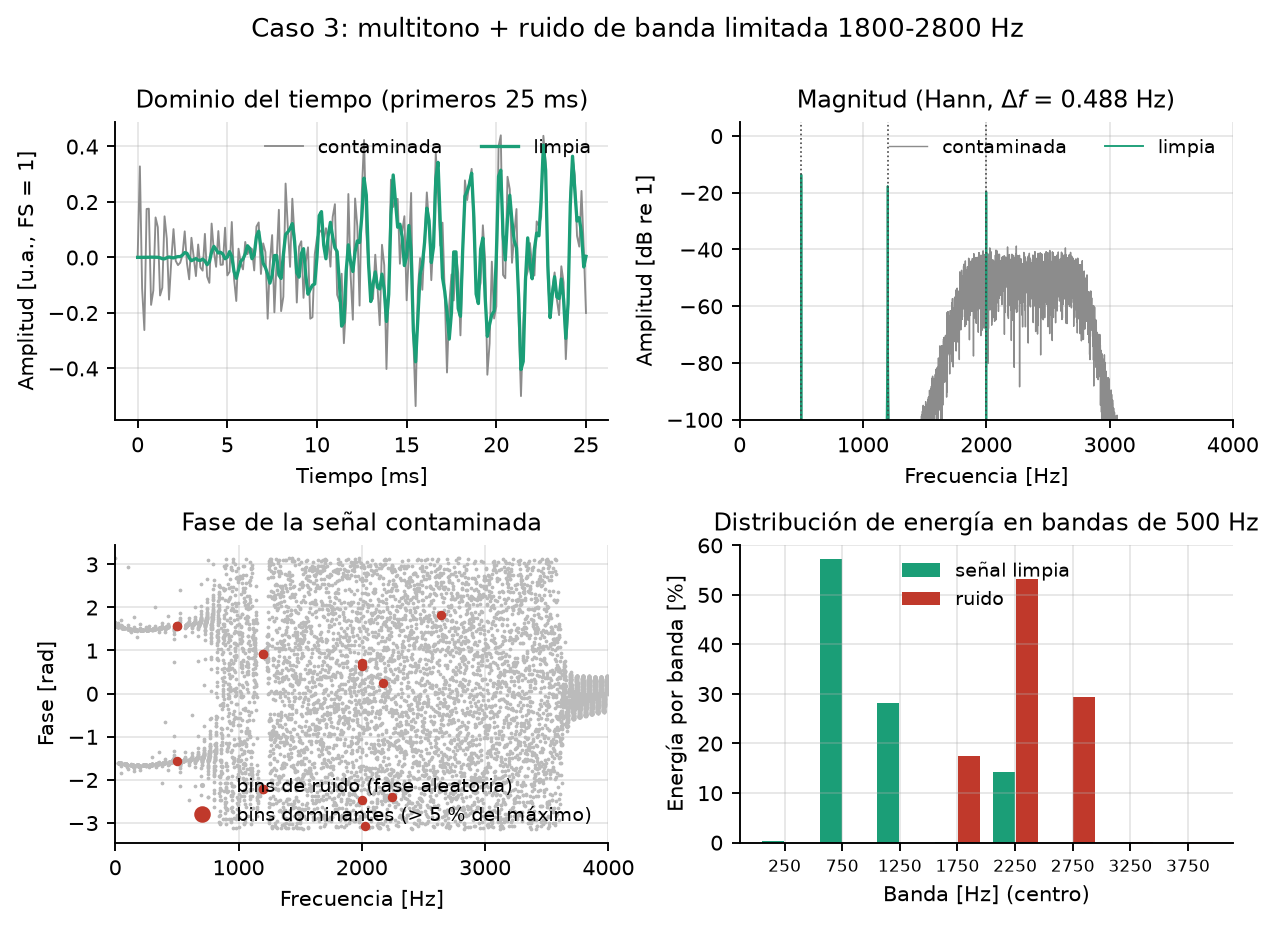

In [23]:
titulos = {"caso_1": "Caso 1: multitono + interferencia senoidal de 3100 Hz",
           "caso_2": "Caso 2: multitono + ruido blanco",
           "caso_3": "Caso 3: multitono + ruido de banda limitada 1800-2800 Hz"}
for nombre in NOMBRES:
    d = datos[nombre]
    ruta = FIG / f"fig_2_2_{nombre}.png"
    gr.fig_caso(titulos[nombre], fs, d["limpia"], d["ruido"], d["contaminada"], ruta, f_utiles=C["frecuencias_utiles_hz"])
    mostrar(ruta)

### (d) Características para identificar el ruido automáticamente

Se calculan sobre el ruido solo (firma del ruido) y se aplica el clasificador del Nodo 1 (`clasificar_ruido`)
**solo sobre la señal contaminada**, mirando la región por encima de la banda útil (2300-4000 Hz).

In [24]:
verdad = {"caso_1": "interferencia tonal", "caso_2": "ruido de banda ancha", "caso_3": "ruido de banda limitada"}
filas, filas_tex = [], []
for nombre in NOMBRES:
    d = datos[nombre]
    cr = fe.caracteristicas_espectrales(d["ruido"], fs)
    tipo, inf = fe.clasificar_ruido(d["contaminada"], fs, tuple(C["banda_util_hz"]), N)
    ok = "sí" if tipo == verdad[nombre] else "NO"
    filas.append([nombre, cr["planitud_espectral"], cr["ancho_banda_99pct_hz"], cr["centroide_hz"],
                  cr["pico_sobre_mediana_dB"], inf["ocupacion_hz"], tipo, ok])
    pl = sci(cr["planitud_espectral"]) if cr["planitud_espectral"] < 1e-2 else f"{cr['planitud_espectral']:.3f}"
    filas_tex.append([nombre.replace("caso_", ""), pl, f"{cr['ancho_banda_99pct_hz']:.0f}", f"{cr['centroide_hz']:.0f}",
                      f"{cr['pico_sobre_mediana_dB']:.1f}", f"{inf['ocupacion_hz']:.0f}", tipo])
    macro("clasif" + ROM[nombre], tipo, "{}")
imprimir_tabla(["caso", "planitud", "ancho 99% [Hz]", "centroide [Hz]", "pico/mediana [dB]",
                "ocupación [Hz]", "tipo detectado", "acierto"], filas, titulo="Características del ruido y clasificación")
tabla_tex("tabla_caracteristicas",
          ["Caso", "Planitud espectral", "Ancho 99 \\% [Hz]", "Centroide [Hz]", "Pico/mediana [dB]", "Ocupación [Hz]", "Tipo detectado (solo con la contaminada)"],
          filas_tex, "ccccccl")


Características del ruido y clasificación
caso     planitud  ancho 99% [Hz]  centroide [Hz]  pico/mediana [dB]  ocupación [Hz]  tipo detectado           acierto
------  ---------  --------------  --------------  -----------------  --------------  -----------------------  -------
caso_1  5.375e-10           46.88            3100              120.1           31.25  interferencia tonal      sí     
caso_2     0.9935            3953            1993              1.163            1703  ruido de banda ancha     sí     
caso_3  6.367e-07            1031            2298              91.61           515.6  ruido de banda limitada  sí     

[tabla_caracteristicas]  versión LaTeX
Caso  Planitud espectral   Ancho 99 \% [Hz]  Centroide [Hz]  Pico/mediana [dB]  Ocupación [Hz]  Tipo detectado (solo con la contaminada)
----  -------------------  ----------------  --------------  -----------------  --------------  ----------------------------------------
1     $5.4\times10^{-10}$  47                310

## 2.3 Diseño de un filtro temporal FIR

Se elige el **Caso 1** (interferencia en 3100 Hz, fuera de la banda útil, que llega hasta 2000 Hz): filtro pasa bajas.
Especificación: banda de paso 0-2200 Hz, banda de rechazo desde 2800 Hz, rizado de paso $\le0.02$ dB,
atenuación $\ge60$ dB. Método: ventana Kaiser, fase lineal (tipo I).

Diseño a 60 dB: 51 coef., atenuación medida 58.93 dB (no cumple)
Diseño a 62 dB: 53 coef., beta = 5.8737, fc = 2500 Hz
rizado de paso = 0.0080 dB (<= 0.02) | atenuación en rechazo = 61.84 dB (>= 60.0)
orden M = 52 | retardo de grupo = 26 muestras = 3.250 ms | suma|h| = 2.0243 | simetría max|h[k]-h[M-k]| = 0.0e+00
|H(3100 Hz)| = -86.7 dB | H(0) = 1.000000

[tabla_coef]  versión LaTeX
$k$  $h[k]=h[52-k]$  $k$  $h[k]=h[52-k]$
---  --------------  ---  --------------
0    +0.00014447     14   -0.01456259   
1    -0.00034640     15   +0.00672029   
2    +0.00000000     16   +0.01494427   
3    +0.00084530     17   -0.02350463   
4    -0.00092667     18   +0.00000000   
5    -0.00069245     19   +0.03449841   
6    +0.00242847     20   -0.03247891   
7    -0.00121920     21   -0.02205083   
8    -0.00290077     22   +0.07467376   
9    +0.00480489     23   -0.03918055   
10   -0.00000000     24   -0.11077261   
11   -0.00744187     25   +0.29292344   
12   +0.00698601     26   +0.62500983   

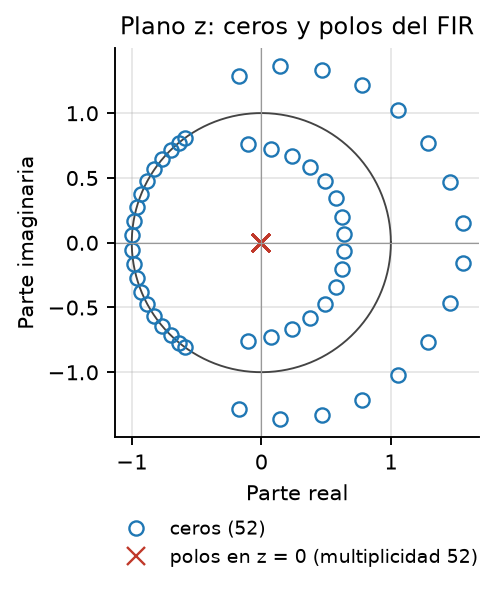

retardo de grupo medio en la banda de paso = 26.0000 muestras (teórico 26)


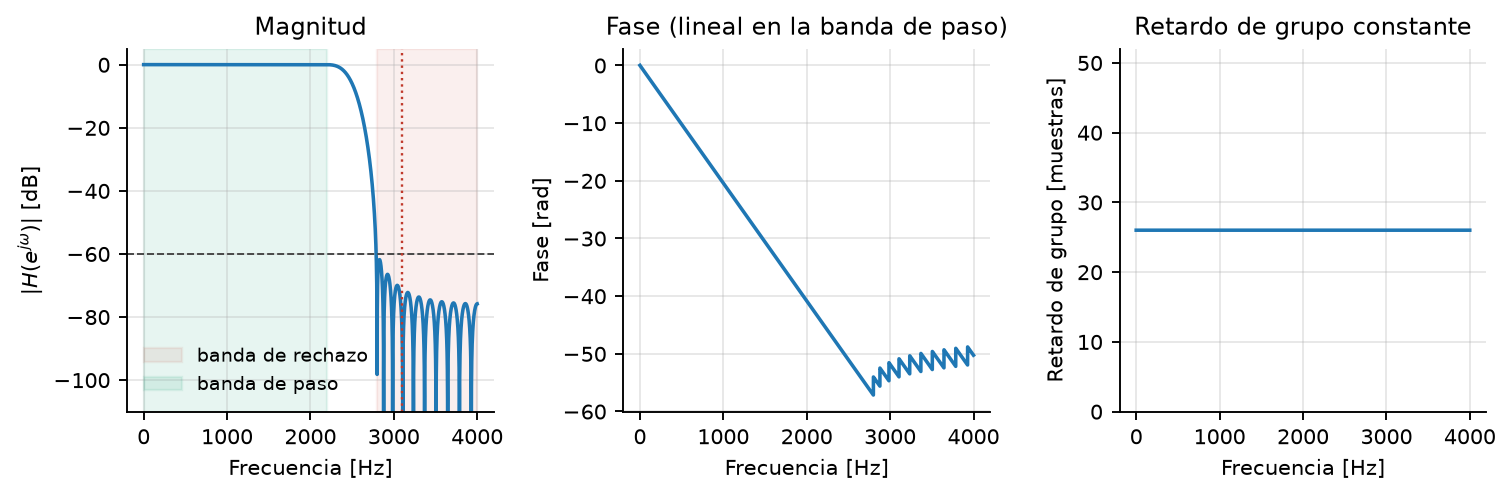

In [25]:
F_PASA, F_RECH, A_RECH, RIZADO_MAX = 2200.0, 2800.0, 60.0, 0.02
# Primer intento con exactamente 60 dB y diseño final con 2 dB de margen
b60, info60 = ft.disenar_fir_kaiser(fs, F_PASA, F_RECH, A_RECH)
esp60 = ft.especificaciones_medidas(b60, fs, F_PASA, F_RECH)
A_DISENO = A_RECH + 2.0
b, info_fir = ft.disenar_fir_kaiser(fs, F_PASA, F_RECH, A_DISENO)
M = len(b) - 1                  # orden
D = M // 2                      # retardo de grupo (muestras)
esp = ft.especificaciones_medidas(b, fs, F_PASA, F_RECH)
print(f"Diseño a 60 dB: {len(b60)} coef., atenuación medida {esp60['atenuacion_rechazo_dB']:.2f} dB (no cumple)")
print(f"Diseño a {A_DISENO:.0f} dB: {len(b)} coef., beta = {info_fir['beta']:.4f}, fc = {info_fir['fc_hz']:.0f} Hz")
print(f"rizado de paso = {esp['rizado_paso_dB']:.4f} dB (<= {RIZADO_MAX}) | atenuación en rechazo = {esp['atenuacion_rechazo_dB']:.2f} dB (>= {A_RECH})")
print(f"orden M = {M} | retardo de grupo = {D} muestras = {1000 * D / fs:.3f} ms | suma|h| = {np.sum(np.abs(b)):.4f} | simetría max|h[k]-h[M-k]| = {np.max(np.abs(b - b[::-1])):.1e}")
print(f"|H(3100 Hz)| = {ft.ganancia_en(b, fs, 3100.0):.1f} dB | H(0) = {np.sum(b):.6f}")

macro("numtaps", str(len(b))); macro("ordenM", str(M)); macro("retDgrupo", str(D)); macro("retDgrupoMs", 1000 * D / fs, "{:.2f}")
macro("betaKaiser", info_fir["beta"], "{:.3f}"); macro("rizadoMedido", esp["rizado_paso_dB"], "{:.4f}")
macro("atenMedida", esp["atenuacion_rechazo_dB"], "{:.1f}"); macro("atenSesenta", esp60["atenuacion_rechazo_dB"], "{:.1f}")
macro("numtapsSesenta", str(len(b60))); macro("gananciaTresmil", ft.ganancia_en(b, fs, 3100.0), "{:.1f}")
macro("sumaAbsH", np.sum(np.abs(b)), "{:.2f}"); macro("hCero", np.sum(b), "{:.4f}")

# Coeficientes (h[k] = h[M-k]); se listan los k = 0..M/2
mitad = M // 2 + 1
izq, der = list(range(0, 14)), list(range(14, mitad))
filas_tex = []
for i in range(max(len(izq), len(der))):
    fila = []
    for grupo in (izq, der):
        fila += [str(grupo[i]), f"{b[grupo[i]]:+.8f}"] if i < len(grupo) else ["", ""]
    filas_tex.append(fila)
hk = f"$h[k]=h[{M}-k]$"
tabla_tex("tabla_coef", ["$k$", hk, "$k$", hk], filas_tex, "rrrr")

# Polos, ceros, estabilidad
ceros, polos = ft.polos_ceros(b, [1.0])
en_circulo = int(np.sum(np.abs(np.abs(ceros) - 1) < 1e-3))
print(f"ceros: {len(ceros)} ({en_circulo} sobre |z|=1 +-1e-3) | polos: {len(polos)} en z=0 | max|polo| = {np.max(np.abs(polos)):.1f} | estable: {ft.es_estable(polos)}")
macro("cerosCirculo", str(en_circulo)); macro("numCeros", str(len(ceros)))
gr.fig_polos_ceros(ceros, polos, FIG / "fig_2_3_polos_ceros.png")
mostrar(FIG / "fig_2_3_polos_ceros.png")

# Respuesta en frecuencia
f_h, H = ft.respuesta_frecuencia(b, [1.0], fs, 8192)
f_gd, gd = ft.retardo_grupo(b, [1.0], fs, 2048)
gd_paso = float(np.mean(gd[f_gd <= F_PASA]))
print(f"retardo de grupo medio en la banda de paso = {gd_paso:.4f} muestras (teórico {D})")
gr.fig_respuesta_fir(f_h, H, f_gd, gd, fs, F_PASA, F_RECH, A_RECH, FIG / "fig_2_3_respuesta.png", f_int=3100.0)
mostrar(FIG / "fig_2_3_respuesta.png")
macro("gdMedio", gd_paso, "{:.3f}")

### Aplicación de la ecuación de diferencias y validación contra la biblioteca

$y[n]=\sum_{k=0}^{52} h[k]\,x[n-k]$ implementada con lazos explícitos (`ecuacion_diferencias`), comparada con `scipy.signal.lfilter`.
Tolerancia declarada: $10^{-12}$ (valor absoluto, señales de amplitud $\le1$, doble precisión).

In [26]:
TOL = 1e-12
sal_fir, filas, filas_tex = {}, [], []
delta = np.zeros(200); delta[0] = 1.0
h_prop = ft.ecuacion_diferencias(b, [1.0], delta)[: len(b)]
print(f"respuesta al impulso de la ecuación de diferencias vs coeficientes: max|dif| = {np.max(np.abs(h_prop - b)):.1e}")
for nombre in NOMBRES:
    x = datos[nombre]["contaminada"]
    t0 = time.perf_counter()
    y_prop = ft.ecuacion_diferencias(b, [1.0], x)
    t_prop = time.perf_counter() - t0
    y_lib = signal.lfilter(b, [1.0], x)
    dif = np.max(np.abs(y_prop - y_lib))
    sal_fir[nombre] = ft.compensar_retardo(y_prop, D)       # se adelanta D muestras
    filas.append([nombre, dif, dif <= TOL, t_prop])
    filas_tex.append([nombre.replace("caso_", ""), sci(dif + 1e-18), "sí" if dif <= TOL else "NO", f"{t_prop:.2f}"])
    macro("difLfilter" + ROM[nombre], dif, "{:.1e}")
imprimir_tabla(["caso", "max|y_propia - y_lfilter|", f"<= {TOL}", "tiempo propia [s]"], filas,
               titulo="Ecuación de diferencias propia vs. lfilter", fmt=[None, None, None, ".2f"])
tabla_tex("tabla_valid_fir", ["Caso", r"$\max|y_{\mathrm{propia}}-y_{\mathrm{lfilter}}|$", r"$\le 10^{-12}$", "Tiempo, lazos Python [s]"], filas_tex, "cccc")
macro("tolFir", TOL, "{:.0e}"); macro("difImpulso", np.max(np.abs(h_prop - b)), "{:.1e}")

respuesta al impulso de la ecuación de diferencias vs coeficientes: max|dif| = 0.0e+00

Ecuación de diferencias propia vs. lfilter
caso    max|y_propia - y_lfilter|  <= 1e-12  tiempo propia [s]
------  -------------------------  --------  -----------------
caso_1                  6.661e-16  sí                     0.14
caso_2                  4.441e-16  sí                     0.14
caso_3                  5.551e-16  sí                     0.14

[tabla_valid_fir]  versión LaTeX
Caso  $\max|y_{\mathrm{propia}}-y_{\mathrm{lfilter}}|$  $\le 10^{-12}$  Tiempo, lazos Python [s]
----  ------------------------------------------------  --------------  ------------------------
1     $6.7\times10^{-16}$                               sí              0.14                    
2     $4.5\times10^{-16}$                               sí              0.14                    
3     $5.6\times10^{-16}$                               sí              0.14                    


### Cuantización de coeficientes, saturación y justificación frente a un IIR

Simulamos coeficientes de 16, 12, 10 y 8 bits (formato Q1.(bits−1)), calculamos el peor caso de saturación y
comparamos con IIR clásicos para la misma plantilla.

In [27]:
x1, s1 = datos["caso_1"]["contaminada"], datos["caso_1"]["limpia"]
y_ref1 = sal_fir["caso_1"]
snr_ref = mt.snr_db_ref(*mt.recortar(s1, y_ref1, E=E_RECORTE))
NOMB_BITS = {16: "Dieciseis", 12: "Doce", 10: "Diez", 8: "Ocho"}
filas = [["64 (float)", 0.0, esp["atenuacion_rechazo_dB"], ft.ganancia_en(b, fs, 3100.0), snr_ref]]
filas_tex = [["64 (float)", "0", f"{esp['atenuacion_rechazo_dB']:.1f}", f"{ft.ganancia_en(b, fs, 3100.0):.1f}", f"{snr_ref:.1f}"]]
for bits in [16, 12, 10, 8]:
    bq, q = ft.cuantizar_coeficientes(b, bits)
    esp_q = ft.especificaciones_medidas(bq, fs, F_PASA, F_RECH)
    yq = ft.compensar_retardo(signal.lfilter(bq, [1.0], x1), D)
    snr_q = mt.snr_db_ref(*mt.recortar(s1, yq, E=E_RECORTE))
    filas.append([bits, np.max(np.abs(bq - b)), esp_q["atenuacion_rechazo_dB"], ft.ganancia_en(bq, fs, 3100.0), snr_q])
    filas_tex.append([bits, sci(np.max(np.abs(bq - b))), f"{esp_q['atenuacion_rechazo_dB']:.1f}", f"{ft.ganancia_en(bq, fs, 3100.0):.1f}", f"{snr_q:.1f}"])
    macro("quantAten" + NOMB_BITS[bits], esp_q["atenuacion_rechazo_dB"], "{:.1f}"); macro("quantSnr" + NOMB_BITS[bits], snr_q, "{:.1f}")
imprimir_tabla(["bits", "max|dif coef|", "atenuación rechazo [dB]", "|H(3100)| [dB]", "SNR salida caso 1 [dB]"], filas,
               titulo="Cuantización de coeficientes (caso 1)", fmt=[None, None, ".1f", ".1f", ".1f"])
tabla_tex("tabla_cuantizacion", ["Bits de coef.", r"$\max|\Delta h|$", "Atenuación mín. en rechazo [dB]", r"$|H(3100\,\mathrm{Hz})|$ [dB]", "SNR de salida, caso 1 [dB]"],
          filas_tex, "crrrr")
macro("snrRefFirUno", snr_ref, "{:.1f}")

# Saturación en el peor caso: la entrada que alinea los signos de h con amplitud pico_maximo FS
pico_peor = C["pico_maximo"] * np.sum(np.abs(b))
print(f"peor caso teórico: {C['pico_maximo']} * sum|h| = {pico_peor:.2f} FS (> 1: se saturaría)")
macro("picoPeorCaso", pico_peor, "{:.2f}")
filas_tex = []
for nombre in NOMBRES:
    filas_tex.append([nombre.replace("caso_", ""), f"{np.abs(datos[nombre]['contaminada']).max():.2f}", f"{np.abs(sal_fir[nombre]).max():.2f}"])
tabla_tex("tabla_picos", ["Señal de prueba", "Pico de entrada [FS]", "Pico de salida [FS]"], filas_tex, "lrr")
macro("picoSalMax", max(np.abs(sal_fir[n]).max() for n in NOMBRES), "{:.2f}")

# IIR equivalentes para la misma plantilla
ord_iir = ft.orden_iir_equivalente(fs, F_PASA, F_RECH, RIZADO_MAX, A_RECH)
filas_tex = [["FIR Kaiser (elegido)", f"{M} ({len(b)} coef.)", str(len(b)), f"lineal (constante, {D} muestras)", "siempre estable"]]
for nom, od in ord_iir.items():
    filas_tex.append([f"IIR {nom}", str(od), str(5 * int(np.ceil(od / 2))), "no lineal", "depende de la cuantización de polos"])
    macro("ordIir" + nom.replace(" ", "").replace("í", "i")[:4], str(od))
imprimir_tabla(["Filtro IIR", "Orden"], list(ord_iir.items()), titulo="Orden de los IIR equivalentes (misma plantilla)")
tabla_tex("tabla_iir", ["Filtro", "Orden", "MAC por muestra", "Fase", "Estabilidad"], filas_tex, "lcclc")


Cuantización de coeficientes (caso 1)
bits        max|dif coef|  atenuación rechazo [dB]  |H(3100)| [dB]  SNR salida caso 1 [dB]
----------  -------------  -----------------------  --------------  ----------------------
64 (float)              0                     61.8           -86.7                    84.3
16              1.479e-05                     62.1           -79.8                    83.6
12              0.0002426                     50.7           -70.5                    60.4
10              0.0009476                     37.1           -69.0                    50.2
8                0.003861                     30.3           -75.7                    36.4

[tabla_cuantizacion]  versión LaTeX
Bits de coef.  $\max|\Delta h|$    Atenuación mín. en rechazo [dB]  $|H(3100\,\mathrm{Hz})|$ [dB]  SNR de salida, caso 1 [dB]
-------------  ------------------  -------------------------------  -----------------------------  --------------------------
64 (float)     0                   

## 2.4 Reducción espectral mediante FFT / IFFT

Cadena: bloque de $N=512$ → ventana Hann → FFT → estimación y modificación espectral → IFFT → solapamiento (50 %) y suma.
Parámetros adaptativos (por bloque): nivel de ruido $\hat\sigma$ (mediana de $|X[k]|$), umbral
$T=\max(\alpha\hat\sigma,\ \tau\max|X|)$ y frecuencia interferente estimada (pico estrecho fuera de la banda útil, sin interpolación).
Se conserva la simetría $G[N-k]=G[k]$ al construir la ganancia.

Parámetros: {'N': 512, 'alpha': 4.0, 'tau': 0.3, 'ext': 2, 'prom': 6.0, 'w': 3, 'banda_util_hz': (300.0, 2300.0)}
reconstrucción con ganancia 1: max|y-x| (interior) = 4.4e-16

Filtrado espectral: resumen por caso
caso    bloques con tono  bloques  f_int media [Hz]  f_int std  σ mediana  T mediana  bins conservados [%]  max|Im(IFFT)|
------  ----------------  -------  ----------------  ---------  ---------  ---------  --------------------  -------------
caso_1                63       63           3093.75       0.00  0.0002337      11.57                   7.0       1.79e-16
caso_2                 0       63                --         --      1.417      8.784                   7.2       1.54e-16
caso_3                 0       63                --         --   0.002764      7.988                   7.4      1.414e-16

[tabla_esp_info]  versión LaTeX
Caso  Bloques con tono detectado  $\hat f_{int}$ [Hz]  $\hat\sigma$ mediana  $T$ mediana  Bins conservados [\%]  $\max|\mathrm{Im}\{\mathrm{IFFT

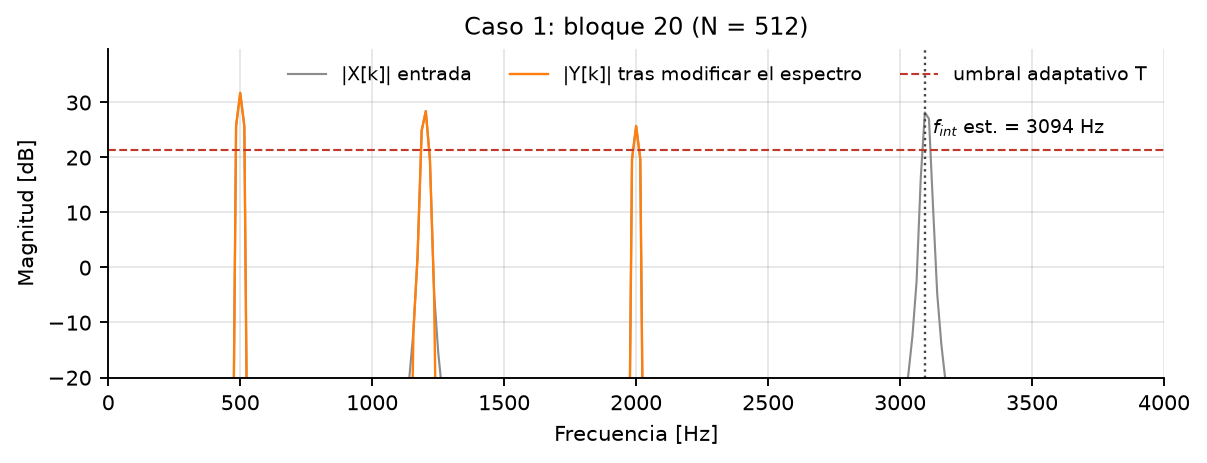

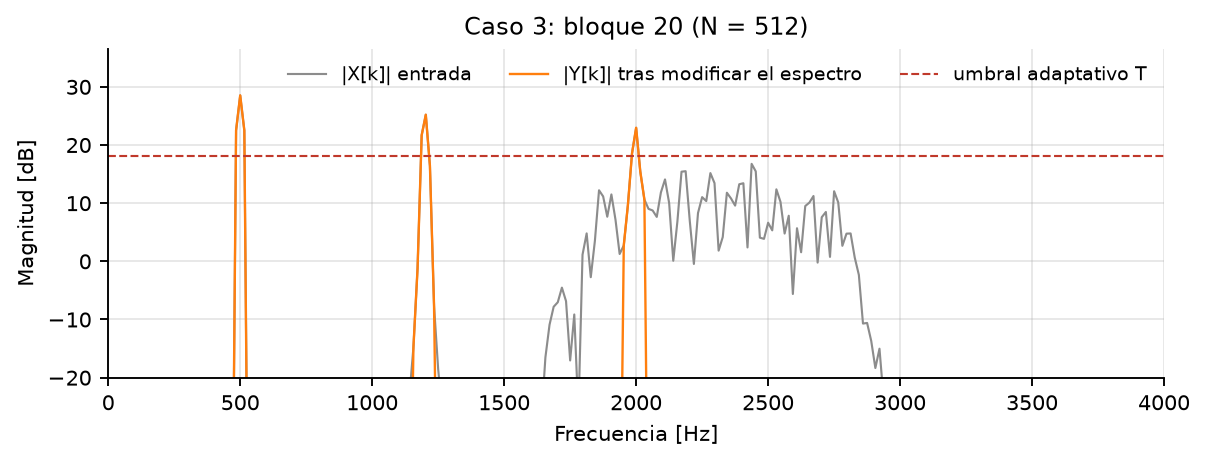

In [28]:
PAR = dict(fe.PARAMETROS_POR_DEFECTO)
print("Parámetros:", {k: v for k, v in PAR.items()})
# Prueba de reconstrucción perfecta: ganancia 1 en todos los bins debe devolver la entrada
x_t = datos["caso_2"]["contaminada"]
y_id, _ = fe.filtrar_espectral(x_t, fs, {"alpha": 0.0, "tau": 0.0, "ext": 0, "prom": 1e18})
err_id = np.max(np.abs((y_id - x_t)[E_RECORTE:-E_RECORTE]))
print(f"reconstrucción con ganancia 1: max|y-x| (interior) = {err_id:.1e}")
macro("errIdentidad", err_id, "{:.1e}")

sal_esp, info_esp, filas, filas_tex = {}, {}, [], []
for nombre in NOMBRES:
    y, inf = fe.filtrar_espectral(datos[nombre]["contaminada"], fs, PAR)
    sal_esp[nombre], info_esp[nombre] = y, inf
    det = ~np.isnan(inf["f_int"])
    f_med = np.nanmean(inf["f_int"]) if det.any() else np.nan
    f_std = np.nanstd(inf["f_int"]) if det.any() else np.nan
    filas.append([nombre, det.sum(), len(det), f_med, f_std, np.median(inf["sigma"]), np.median(inf["T"]),
                  100 * inf["frac_bins_conservados"].mean(), inf["max_imag"].max()])
    fi = f"{f_med:.2f} $\\pm$ {f_std:.2f}" if det.any() else "--"
    filas_tex.append([nombre.replace("caso_", ""), f"{det.sum()}/{len(det)}", fi, f"{np.median(inf['sigma']):.3g}",
                      f"{np.median(inf['T']):.3g}", f"{100 * inf['frac_bins_conservados'].mean():.1f}", sci(inf["max_imag"].max())])
    macro("detecta" + ROM[nombre], f"{det.sum()}/{len(det)}", "{}")
    if det.any():
        macro("fIntEst" + ROM[nombre], f_med, "{:.2f}")
    macro("maxImag" + ROM[nombre], inf["max_imag"].max(), "{:.0e}")
imprimir_tabla(["caso", "bloques con tono", "bloques", "f_int media [Hz]", "f_int std", "σ mediana",
                "T mediana", "bins conservados [%]", "max|Im(IFFT)|"], filas, titulo="Filtrado espectral: resumen por caso",
               fmt=[None, None, None, ".2f", ".2f", None, None, ".1f", None])
tabla_tex("tabla_esp_info", ["Caso", "Bloques con tono detectado", r"$\hat f_{int}$ [Hz]", r"$\hat\sigma$ mediana", "$T$ mediana",
                             "Bins conservados [\\%]", r"$\max|\mathrm{Im}\{\mathrm{IFFT}\}|$"], filas_tex, "ccccccc")

for nombre in ("caso_1", "caso_3"):
    idx = 20
    xb = datos[nombre]["contaminada"][idx * HOP: idx * HOP + N]
    yb, inf = fe.procesar_bloque(xb, fs, PAR)
    ruta = FIG / f"fig_2_4_bloque_{nombre}.png"
    gr.fig_bloque_espectral(fs, N, xb, yb, inf["T"], inf["f_int"], ruta, titulo=f"{ETIQ[nombre]}: bloque {idx} (N = {N})")
    mostrar(ruta)

### Compromiso entre eliminar ruido y distorsionar la señal útil

Se barren los parámetros del umbral. "Energía de entrada eliminada" crece con el umbral, pero cuando el umbral supera
la amplitud de un tono útil también se elimina señal: la energía útil conservada cae y $\Delta$SNR se desploma.

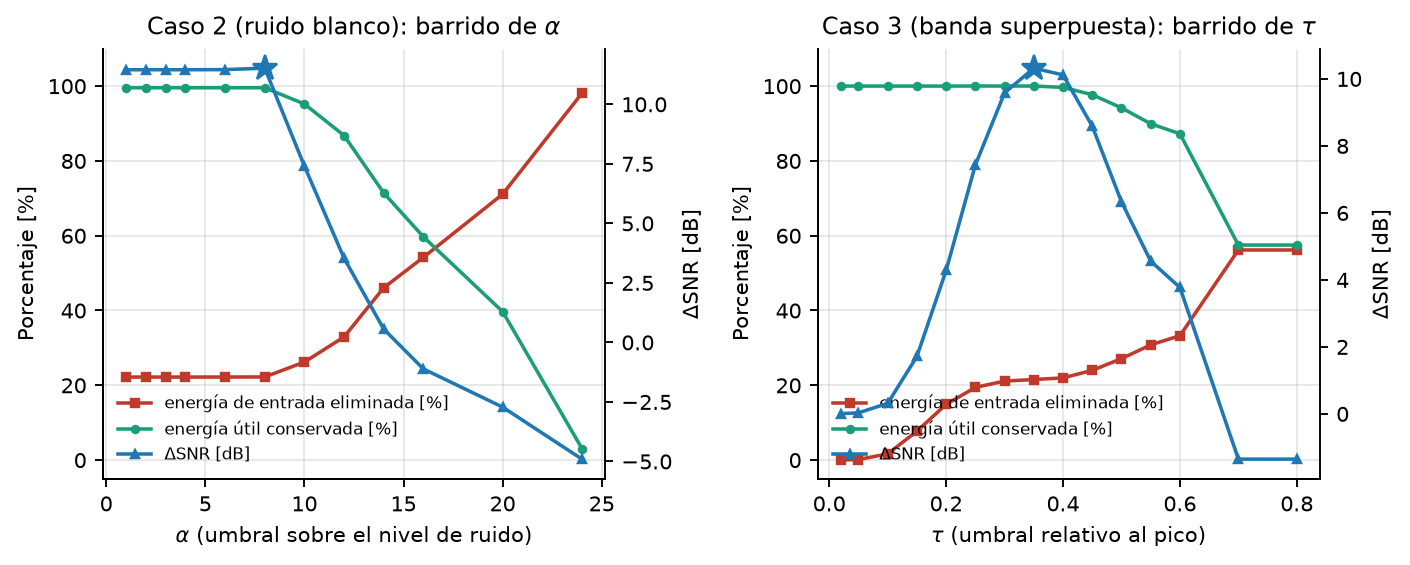


[tabla_compromiso]  versión LaTeX
Barrido            Valor  Energía de entrada eliminada [\%]  Energía útil conservada [\%]  $\Delta$SNR [dB]
-----------------  -----  ---------------------------------  ----------------------------  ----------------
$\alpha$ (caso 2)  4      22.2                               99.5                          +11.4           
$\alpha$ (caso 2)  8      22.2                               99.5                          +11.5           
$\alpha$ (caso 2)  12     32.9                               86.8                          +3.5            
$\alpha$ (caso 2)  16     54.2                               59.7                          -1.1            
$\alpha$ (caso 2)  24     98.1                               3.1                           -4.9            
$\tau$ (caso 3)    0.3    21.1                               100.0                         +9.6            
$\tau$ (caso 3)    0.4    22.0                               99.6                          +10.1     

In [29]:
def barrer(nombre, clave, valores):
    d = datos[nombre]
    s, x = d["limpia"], d["contaminada"]
    res = {"x": np.array(valores, dtype=float), "dsnr": [], "eutil": [], "eliminada": []}
    for v in valores:
        y, _ = fe.filtrar_espectral(x, fs, {clave: v})
        s_, x_, y_ = mt.recortar(s, x, y, E=E_RECORTE)
        res["dsnr"].append(mt.snr_db_ref(s_, y_) - mt.snr_db_ref(s_, x_))
        res["eutil"].append(mt.energia_util_conservada(s_, y_))
        res["eliminada"].append(100 * (1 - mt.energia(y_) / mt.energia(x_)))
    for k in ("dsnr", "eutil", "eliminada"):
        res[k] = np.array(res[k])
    return res

res_alpha = barrer("caso_2", "alpha", [1, 2, 3, 4, 6, 8, 10, 12, 14, 16, 20, 24])
res_tau = barrer("caso_3", "tau", [0.02, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7, 0.8])
COLS_BARRIDO = ["parametro", "x", "dsnr", "eutil", "eliminada"]
filas_barrido = [{"parametro": etiqueta, "x": x, "dsnr": ds, "eutil": eu, "eliminada": el}
                 for etiqueta, res in (("alpha (caso 2)", res_alpha), ("tau (caso 3)", res_tau))
                 for x, ds, eu, el in zip(res["x"], res["dsnr"], res["eutil"], res["eliminada"])]
guardar_csv(RAIZ / "resultados" / "barrido_compromiso.csv", COLS_BARRIDO, filas_barrido, formato_float=None)
gr.fig_compromiso(res_alpha, res_tau, FIG / "fig_2_4_compromiso.png")
mostrar(FIG / "fig_2_4_compromiso.png")

def fila_barrido(res, v):
    i = int(np.argmin(np.abs(res["x"] - v)))
    return [f"{res['x'][i]:g}", f"{res['eliminada'][i]:.1f}", f"{res['eutil'][i]:.1f}", f"{res['dsnr'][i]:+.1f}"]

filas_tex = [[r"$\alpha$ (caso 2)"] + fila_barrido(res_alpha, v) for v in (4, 8, 12, 16, 24)]
filas_tex += [[r"$\tau$ (caso 3)"] + fila_barrido(res_tau, v) for v in (0.3, 0.4, 0.5, 0.6, 0.8)]
tabla_tex("tabla_compromiso", ["Barrido", "Valor", "Energía de entrada eliminada [\\%]", "Energía útil conservada [\\%]", r"$\Delta$SNR [dB]"], filas_tex, "lrrrr")
ia, it = int(np.argmax(res_alpha["dsnr"])), int(np.argmax(res_tau["dsnr"]))
macro("alphaMejor", res_alpha["x"][ia], "{:g}"); macro("dsnrAlphaMejor", res_alpha["dsnr"][ia], "{:.1f}")
macro("tauMejor", res_tau["x"][it], "{:g}"); macro("dsnrTauMejor", res_tau["dsnr"][it], "{:.1f}")
j = int(np.argmin(np.abs(res_alpha["x"] - 24)))
macro("elimAlphaMax", res_alpha["eliminada"][j], "{:.1f}"); macro("eutilAlphaMax", res_alpha["eutil"][j], "{:.1f}"); macro("dsnrAlphaMax", res_alpha["dsnr"][j], "{:+.1f}")
j = int(np.argmin(np.abs(res_tau["x"] - 0.8)))
macro("elimTauMax", res_tau["eliminada"][j], "{:.1f}"); macro("eutilTauMax", res_tau["eutil"][j], "{:.1f}"); macro("dsnrTauMax", res_tau["dsnr"][j], "{:+.1f}")

## 2.5 Comparación y propuesta para el sistema embebido

Todas las métricas se calculan sobre el segmento interior (se descartan 512 muestras en cada extremo, mismo recorte
para todas las salidas) y la salida del FIR se alinea compensando su retardo de grupo (26 muestras).
Bandas de la "interferencia dominante": Caso 1 = 3050-3150 Hz; Caso 2 = 2300-4000 Hz (sin señal útil, solo ruido);
Caso 3 = 1800-2800 Hz (banda del ruido).


Métricas por caso y método
caso    metodo           MSE  SNR_entrada_dB  SNR_salida_dB  Delta_SNR_dB  energia_util_conservada_pct  atenuacion_interferencia_dB  banda_interferencia_hz
------  ---------  ---------  --------------  -------------  ------------  ---------------------------  ---------------------------  ----------------------
Caso 1  Entrada      0.02468           5.053          5.053             0                          100                            0  3050-3150             
Caso 1  FIR         2.95e-10           5.053          84.28         79.23                          100                        86.72  3050-3150             
Caso 1  Espectral  3.315e-07           5.053          53.77         48.72                          100                        94.91  3050-3150             
Caso 2  Entrada      0.01425           5.067          5.067             0                         99.5                            0  2300-4000             
Caso 2  FIR         0.008683        

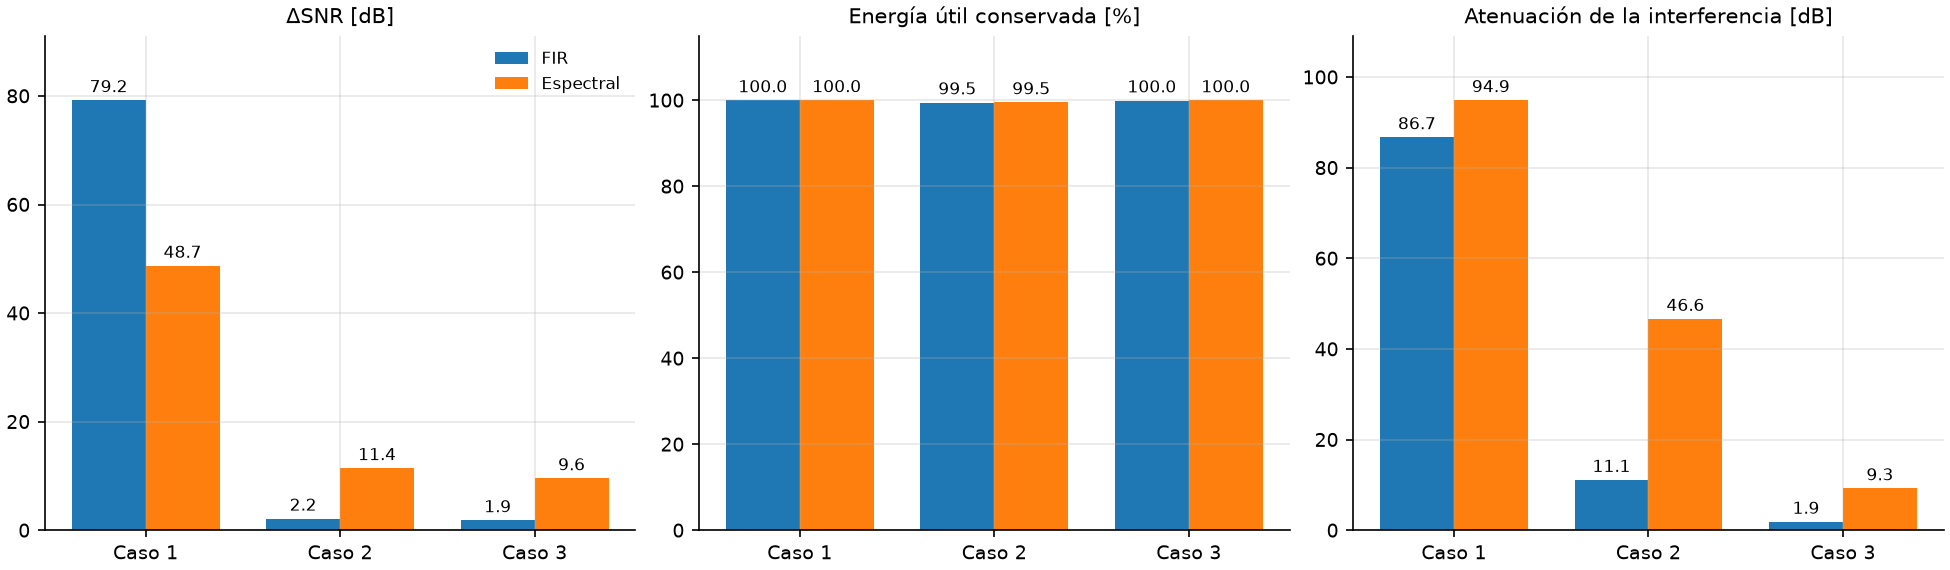

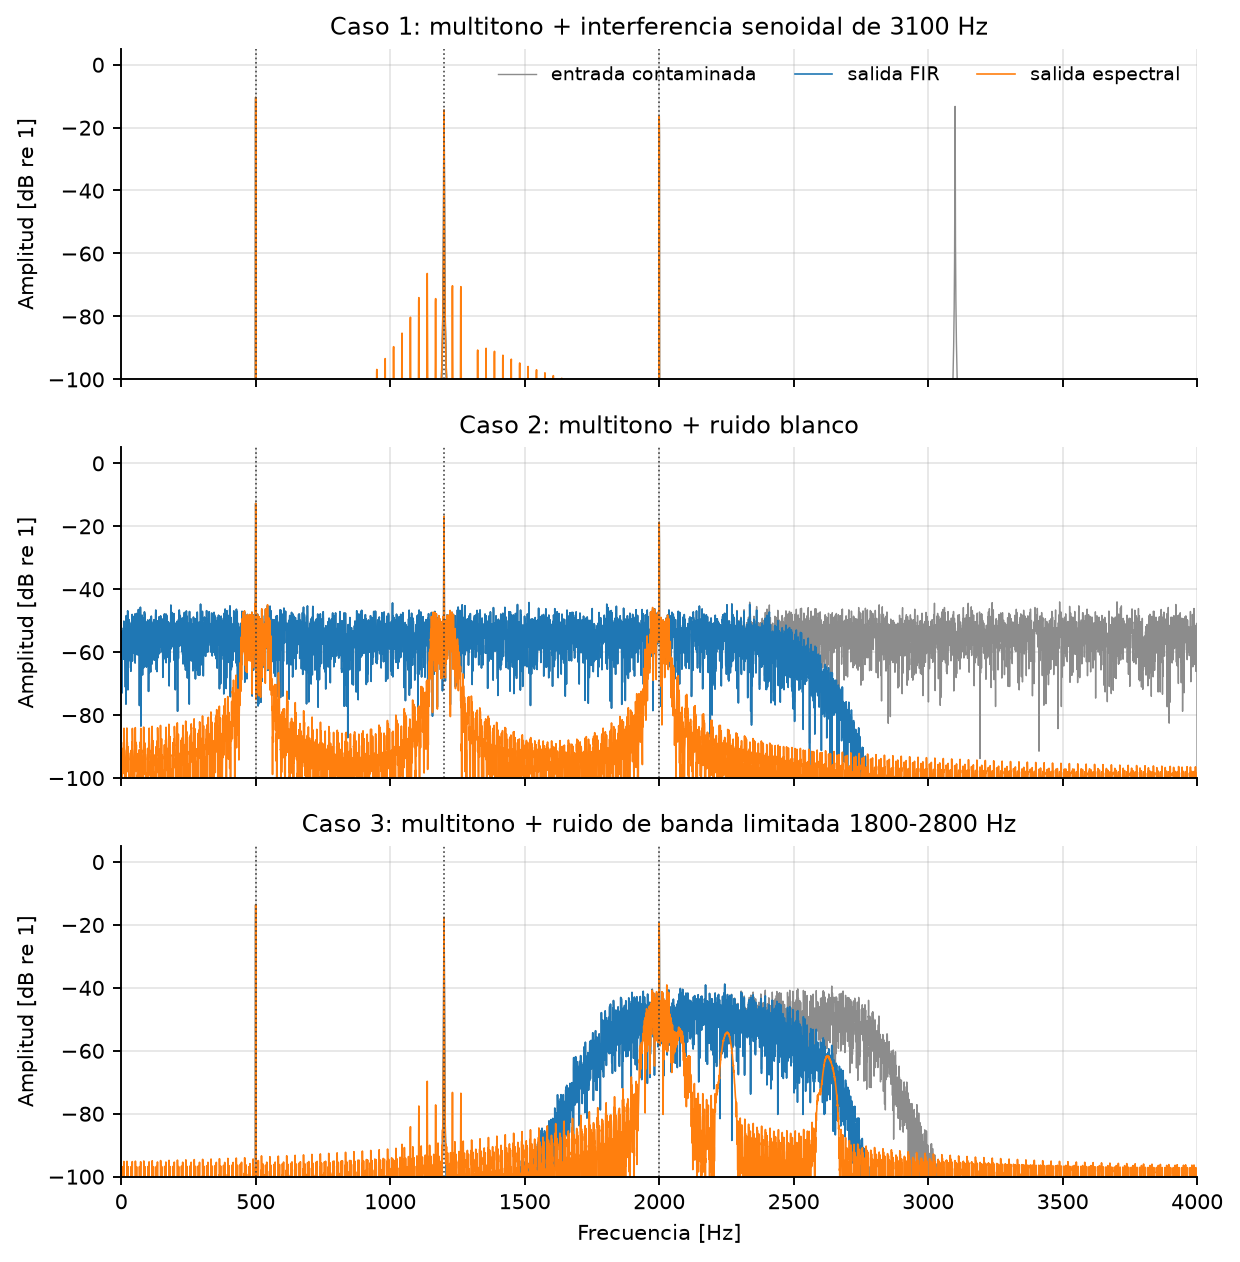

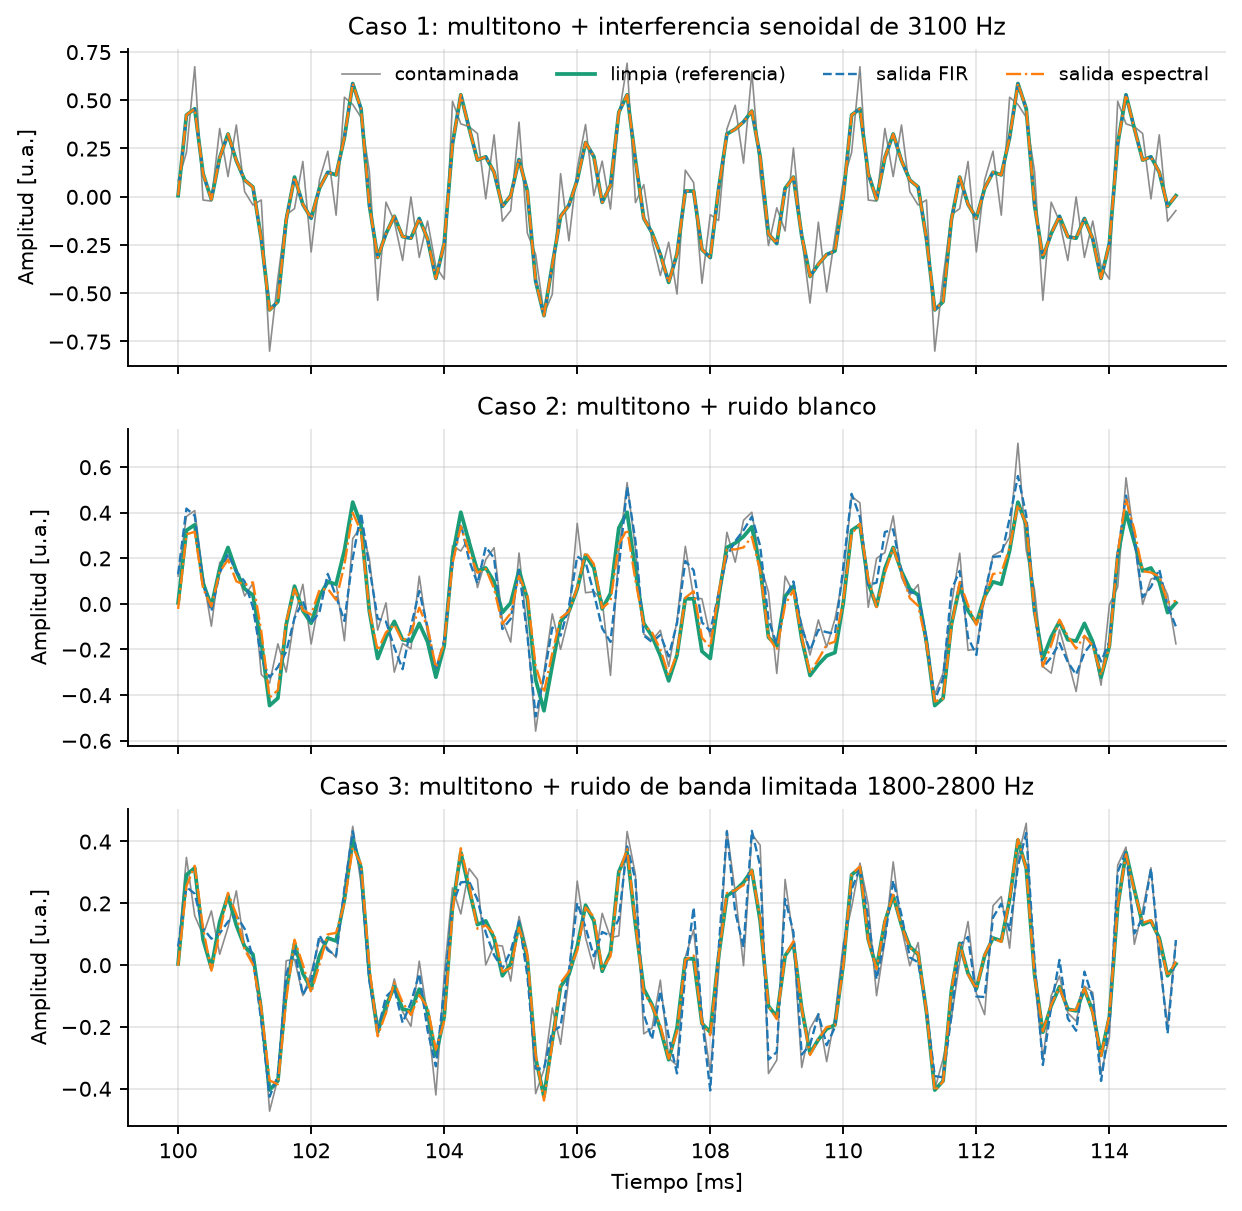

In [30]:
BANDA_INT = {"caso_1": (3050.0, 3150.0), "caso_2": (2300.0, 4000.0), "caso_3": (1800.0, 2800.0)}
filas_m = []
for nombre in NOMBRES:
    d = datos[nombre]
    for metodo, y in [("Entrada", d["contaminada"]), ("FIR", sal_fir[nombre]), ("Espectral", sal_esp[nombre])]:
        r = mt.evaluar(d["limpia"], d["ruido"], d["contaminada"], y, fs, BANDA_INT[nombre], E_RECORTE)
        filas_m.append({"caso": ETIQ[nombre], "metodo": metodo, **r,
                        "banda_interferencia_hz": f"{BANDA_INT[nombre][0]:.0f}-{BANDA_INT[nombre][1]:.0f}"})
COLS_M = list(filas_m[0])
imprimir_tabla(COLS_M, [[f[c] for c in COLS_M] for f in filas_m], titulo="Métricas por caso y método")
por_caso = {(f["caso"], f["metodo"]): f for f in filas_m}

for nm in NOMBRES:
    for metodo, abrev in (("FIR", "Fir"), ("Espectral", "Esp")):
        r = por_caso[(ETIQ[nm], metodo)]
        pref = abrev + ROM[nm]
        macro("dsnr" + pref, r["Delta_SNR_dB"], "{:.1f}"); macro("snrOut" + pref, r["SNR_salida_dB"], "{:.1f}")
        macro("eutil" + pref, r["energia_util_conservada_pct"], "{:.1f}"); macro("aten" + pref, r["atenuacion_interferencia_dB"], "{:.1f}")
        macro("mse" + pref, r["MSE"], "{:.1e}")
for nm in NOMBRES:
    r = por_caso[(ETIQ[nm], "Entrada")]
    macro("snrIn" + ROM[nm], r["SNR_entrada_dB"], "{:.2f}"); macro("mseIn" + ROM[nm], r["MSE"], "{:.1e}")


def fig_barras_metricas(por_caso, ruta):
    """Barras agrupadas por caso (FIR vs. espectral) para tres métricas de la comparación."""
    paneles = [("Delta_SNR_dB", r"$\Delta$SNR [dB]"),
               ("energia_util_conservada_pct", "Energía útil conservada [%]"),
               ("atenuacion_interferencia_dB", "Atenuación de la interferencia [dB]")]
    metodos, ancho = ("FIR", "Espectral"), 0.38
    x = np.arange(len(NOMBRES))
    fig, ejes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
    for ax, (clave, titulo) in zip(ejes, paneles):
        for i, metodo in enumerate(metodos):
            valores = [por_caso[(ETIQ[n], metodo)][clave] for n in NOMBRES]
            barras = ax.bar(x + (i - 0.5) * ancho, valores, ancho, label=metodo)
            ax.bar_label(barras, fmt="%.1f", fontsize=8, padding=2)
        ax.set_xticks(x, [ETIQ[n] for n in NOMBRES])
        ax.set_title(titulo, fontsize=10)
        ax.grid(axis="y", alpha=0.3)
        ax.margins(y=0.15)
    ejes[0].legend(frameon=False)
    fig.savefig(ruta, dpi=150)
    plt.close(fig)


fig_barras_metricas(por_caso, FIG / "fig_2_5_metricas.png")
mostrar(FIG / "fig_2_5_metricas.png")

# Figuras de salida: espectros y forma de onda
datos_esp = [(titulos[n], datos[n]["contaminada"], sal_fir[n], sal_esp[n]) for n in NOMBRES]
gr.fig_espectros_salida(datos_esp, fs, FIG / "fig_2_5_espectros.png", f_utiles=C["frecuencias_utiles_hz"])
mostrar(FIG / "fig_2_5_espectros.png")
datos_t = [(titulos[n], datos[n]["limpia"], datos[n]["contaminada"], sal_fir[n], sal_esp[n]) for n in NOMBRES]
gr.fig_tiempo_salidas(datos_t, fs, FIG / "fig_2_5_tiempo.png")
mostrar(FIG / "fig_2_5_tiempo.png")

### Tiempo de ejecución, memoria y comunicación

Los tiempos "PC" se midieron en Python y **solo sirven como referencia relativa**. Los del microcontrolador son una
**estimación por conteo de operaciones** (supuestos explícitos abajo) que debe validarse midiendo ciclos en el hardware.
Hardware supuesto: STM32F407 (Cortex-M4F, 168 MHz, 192 kB SRAM, ADC/DAC de 12 bits).

In [31]:
xb256 = datos["caso_2"]["contaminada"][:HOP]
xb512 = datos["caso_2"]["contaminada"][:N]
t_fir_prop = medir_ms(lambda: ft.ecuacion_diferencias(b, [1.0], xb256), 10)
t_fir_lib = medir_ms(lambda: signal.lfilter(b, [1.0], xb256), 300)
t_esp_prop = medir_ms(lambda: fe.procesar_bloque(xb512, fs, PAR), 50)
t_esp_np = medir_ms(lambda: fe.procesar_bloque(xb512, fs, PAR, fft=np.fft.fft, ifft=np.fft.ifft), 300)
print(f"FIR  (256 muestras): lazos Python {t_fir_prop:.2f} ms | lfilter {t_fir_lib:.3f} ms")
print(f"ESP. (bloque 512)  : FFT propia {t_esp_prop:.2f} ms | FFT numpy {t_esp_np:.3f} ms")

# Estimación MCU por conteo de operaciones
F_CPU, CICLOS_OP = 168e6, 3.0                        # supuesto conservador: 3 ciclos por operación float32
ops_fir = len(b) * HOP                               # MAC por salto de 256 muestras
ops_fft = 5 * (N // 2) * np.log2(N // 2) + N         # FFT real de N puntos usando FFT compleja de N/2 (+N de post-proceso)
ops_esp = 2 * ops_fft + 40 * (N // 2 + 1) + N        # FFT + IFFT + ~40 ops/bin (|X|, mediana, umbral, máscara, solape) + ventana
t_fir_mcu = ops_fir * CICLOS_OP / F_CPU * 1000
t_esp_mcu = ops_esp * CICLOS_OP / F_CPU * 1000
t_hop_ms = 1000 * HOP / fs
print(f"MCU estimado: FIR {ops_fir:.0f} ops -> {t_fir_mcu:.2f} ms ({100 * t_fir_mcu / t_hop_ms:.1f} % del salto) | "
      f"espectral {ops_esp:.0f} ops -> {t_esp_mcu:.2f} ms ({100 * t_esp_mcu / t_hop_ms:.1f} % del salto de {t_hop_ms:.0f} ms)")

# Memoria RAM aproximada (float32, bytes)
mem_fir = {"coeficientes (53 x 4 B)": len(b) * 4,
           "estado arm_fir_f32 (53+256-1 muestras)": (len(b) + HOP - 1) * 4,
           "buffers E/S (2 x 256 x 4 B)": 2 * HOP * 4}
mem_esp = {"ventana Hann (512 x 4 B)": N * 4, "buffer FFT in situ (512 x 4 B)": N * 4,
           "magnitud (257 x 4 B)": (N // 2 + 1) * 4, "solapamiento (256 x 4 B)": HOP * 4,
           "entrada y salida de un salto (2 x 256 x 4 B)": 2 * HOP * 4}
ram_fir, ram_esp = sum(mem_fir.values()), sum(mem_esp.values())
print("RAM FIR:", ram_fir, "B |", "RAM espectral:", ram_esp, "B")

filas_tex = [[f"FIR ({len(b)} coef.)", f"{ops_fir:,}".replace(",", r"\,"), f"{t_fir_prop:.2f} / {t_fir_lib:.3f}", f"{t_fir_mcu:.2f}", f"{ram_fir:,}".replace(",", r"\,")],
             ["Espectral ($N=512$)", f"{ops_esp:,.0f}".replace(",", r"\,"), f"{t_esp_prop:.2f} / {t_esp_np:.3f}", f"{t_esp_mcu:.2f}", f"{ram_esp:,}".replace(",", r"\,")]]
tabla_tex("tabla_costos", ["Método", "Operaciones por salto", "PC [ms] (propia / biblioteca)", "MCU estimado [ms]", "RAM aprox. [B]"], filas_tex, "lrrrr")
for nom, v, f_ in [("tFirProp", t_fir_prop, "{:.2f}"), ("tFirLib", t_fir_lib, "{:.3f}"), ("tEspProp", t_esp_prop, "{:.2f}"),
                   ("tEspNp", t_esp_np, "{:.3f}"), ("tFirMcu", t_fir_mcu, "{:.2f}"), ("tEspMcu", t_esp_mcu, "{:.2f}"),
                   ("opsFir", ops_fir, "{:.0f}"), ("opsEsp", ops_esp, "{:.0f}"), ("ramFir", ram_fir, "{:.0f}"), ("ramEsp", ram_esp, "{:.0f}"),
                   ("utilFir", 100 * t_fir_mcu / t_hop_ms, "{:.1f}"), ("utilEsp", 100 * t_esp_mcu / t_hop_ms, "{:.1f}"),
                   ("tHop", t_hop_ms, "{:.0f}")]:
    macro(nom, v, f_)

# Comunicación entre nodos (UART 8N1 = 10 bits por byte)
ENC = 2 + 2 + 2 + 2                       # SYNC 0xAA55 + SEQ + LEN + CRC16
carga_muestras = HOP * 2                  # 256 muestras int16
carga_param = 1 + 2 + 4 + 1               # tipo de ruido, f_int (Hz), sigma (float32), banderas
bloques_s = fs / HOP
enlaces = [("Nodo 1 $\\to$ Nodo 2", "256 muestras int16", carga_muestras + ENC, 0),
           ("Nodo 1 $\\to$ Nodo 3", "256 muestras int16 + parámetros", carga_muestras + ENC, carga_param + ENC),
           ("Nodo 2 $\\to$ Nodo 3", "256 muestras filtradas int16", carga_muestras + ENC, 0)]
filas_tex = []
for nom, cont, b1, b2 in enlaces:
    tot = b1 + b2
    filas_tex.append([nom, cont, tot, f"{bloques_s:.2f}", f"{tot * bloques_s:,.0f}".replace(",", r"\,"), f"{tot * bloques_s * 10 / 1000:.1f}"])
tabla_tex("tabla_comunicacion", ["Enlace", "Contenido por salto", "Bytes por salto", "Saltos/s", "Bytes/s", "Tasa mínima UART 8N1 [kbit/s]"], filas_tex, "llrrrr")
tasa_max = max((b1 + b2) * bloques_s * 10 / 1000 for _, _, b1, b2 in enlaces)
print(f"bytes por salto: {[b1 + b2 for _, _, b1, b2 in enlaces]} | tasa mínima máxima = {tasa_max:.1f} kbit/s")
macro("tasaMinima", tasa_max, "{:.1f}"); macro("bytesSalto", carga_muestras + ENC, "{:.0f}"); macro("bytesSaltoParam", carga_muestras + ENC + carga_param + ENC, "{:.0f}")
macro("saltosPorS", bloques_s, "{:.2f}"); macro("bytesParam", carga_param + ENC, "{:.0f}")

FIR  (256 muestras): lazos Python 1.81 ms | lfilter 0.013 ms
ESP. (bloque 512)  : FFT propia 0.29 ms | FFT numpy 0.063 ms
MCU estimado: FIR 13568 ops -> 0.24 ms (0.8 % del salto) | espectral 32296 ops -> 0.58 ms (1.8 % del salto de 32 ms)
RAM FIR: 3492 B | RAM espectral: 8196 B

[tabla_costos]  versión LaTeX
Método               Operaciones por salto  PC [ms] (propia / biblioteca)  MCU estimado [ms]  RAM aprox. [B]
-------------------  ---------------------  -----------------------------  -----------------  --------------
FIR (53 coef.)       13\,568                1.81 / 0.013                   0.24               3\,492        
Espectral ($N=512$)  32\,296                0.29 / 0.063                   0.58               8\,196        

[tabla_comunicacion]  versión LaTeX
Enlace               Contenido por salto              Bytes por salto  Saltos/s  Bytes/s  Tasa mínima UART 8N1 [kbit/s]
-------------------  -------------------------------  ---------------  --------  -------  -------

### Exportación: `metricas.csv`, `configuraciones.json` y macros para el informe

In [32]:
extra = {"FIR": {"tiempo_bloque_PC_ms": t_fir_lib, "tiempo_bloque_MCU_est_ms": t_fir_mcu, "RAM_aprox_B": ram_fir},
         "Espectral": {"tiempo_bloque_PC_ms": t_esp_np, "tiempo_bloque_MCU_est_ms": t_esp_mcu, "RAM_aprox_B": ram_esp}}
COLS_EXTRA = ["tiempo_bloque_PC_ms", "tiempo_bloque_MCU_est_ms", "RAM_aprox_B"]
filas_out = [{**f, **{c: extra.get(f["metodo"], {}).get(c, np.nan) for c in COLS_EXTRA}} for f in filas_m]
guardar_csv(RAIZ / "resultados" / "metricas.csv", COLS_M + COLS_EXTRA, filas_out, formato_float="%.6g")
imprimir_tabla(["caso", "metodo"] + COLS_EXTRA, [[f["caso"], f["metodo"]] + [f[c] for c in COLS_EXTRA] for f in filas_out],
               titulo="metricas.csv: costo por método (además de las métricas ya mostradas)")

filas_tex = []
for r in filas_m:
    filas_tex.append([r["caso"].replace("Caso ", ""), r["metodo"], sci(r["MSE"]), f"{r['SNR_entrada_dB']:.2f}", f"{r['SNR_salida_dB']:.2f}",
                      f"{r['Delta_SNR_dB']:.2f}", f"{r['energia_util_conservada_pct']:.1f}", f"{r['atenuacion_interferencia_dB']:.1f}"])
tabla_tex("tabla_metricas", ["Caso", "Método", "MSE", "SNR ent. [dB]", "SNR sal. [dB]", r"$\Delta$SNR [dB]", "E. útil [\\%]", "Atenuación interf. [dB]"],
          filas_tex, "clcrrrrr")

CONFIG["filtro_fir"] = {"tipo": "FIR pasa bajas, fase lineal tipo I, ventana Kaiser", "fs_hz": fs, "banda_paso_hz": [0, F_PASA],
                        "banda_rechazo_hz": [F_RECH, fs / 2], "rizado_max_db": RIZADO_MAX, "atenuacion_min_db": A_RECH,
                        "atenuacion_diseno_db": A_DISENO, "numtaps": len(b), "orden": M, "beta_kaiser": info_fir["beta"],
                        "fc_hz": info_fir["fc_hz"], "retardo_grupo_muestras": D, "rizado_medido_db": esp["rizado_paso_dB"],
                        "atenuacion_medida_db": esp["atenuacion_rechazo_dB"], "coeficientes": [float(v) for v in b],
                        "tolerancia_validacion": TOL}
CONFIG["filtrado_espectral"] = {k: (list(v) if isinstance(v, tuple) else v) for k, v in PAR.items()}
CONFIG["filtrado_espectral"]["solapamiento"] = "50 % (salto N/2), ventana Hann periodica, suma por solapamiento"
CONFIG["metricas"] = {"recorte_extremos_muestras": E_RECORTE, "bandas_interferencia_hz": {k: list(v) for k, v in BANDA_INT.items()},
                      "energia_util_conservada": "100 * <s_hat, s> / <s, s>"}
CONFIG["hardware_supuesto"] = {"mcu": "STM32F407 (Cortex-M4F, 168 MHz)", "ciclos_por_operacion_supuestos": CICLOS_OP,
                               "formato_transporte": "int16 Q15", "enlace": "UART 8N1", "baudios_propuestos": 460800}
sg.guardar_json(RAIZ / "metadatos" / "configuraciones.json", CONFIG)


metricas.csv: costo por método (además de las métricas ya mostradas)
caso    metodo     tiempo_bloque_PC_ms  tiempo_bloque_MCU_est_ms  RAM_aprox_B
------  ---------  -------------------  ------------------------  -----------
Caso 1  Entrada                     --                        --           --
Caso 1  FIR                     0.0135                    0.2423         3492
Caso 1  Espectral               0.0626                    0.5767         8196
Caso 2  Entrada                     --                        --           --
Caso 2  FIR                     0.0135                    0.2423         3492
Caso 2  Espectral               0.0626                    0.5767         8196
Caso 3  Entrada                     --                        --           --
Caso 3  FIR                     0.0135                    0.2423         3492
Caso 3  Espectral               0.0626                    0.5767         8196

[tabla_metricas]  versión LaTeX
Caso  Método     MSE                  S